# Projekt 1 – Rating/Scoring: modele, wyjaśnialność, kalibracja 4%, ratingi (pkt 3.3–3.6)

**Notebook 02.** Wymaga uruchomionego notebooka 01 (katalog `artifacts/` oraz `src/preprocessing.py`).

Zawartość:
0. Konfiguracja, wczytanie artefaktów
1. **3.3 Model interpretowalny** – scorecard: regresja logistyczna na WoE (selekcja po znaku i VIF), jakość, interpretacja globalna i lokalna, stabilność
2. **3.4 Model black-box** – LightGBM, tuning z kontrolą overfittingu, SHAP, LIME, what-if
3. **Wierność i stabilność wyjaśnień** (eksperymenty obowiązkowe)
4. Porównanie modeli i zamrożenie modeli
5. **3.5 Kalibracja** – statystyczna (Platt / izotoniczna / beta) i dostosowanie do PD = 4%
6. **3.6 Progi decyzji, ratingi, audyt podgrup, analiza kontrfaktyczna**
7. Podsumowanie, eksport, `requirements.txt`

**Zasada nadrzędna:** wszystkie wybory (cechy, hiperparametry, kalibrator, korekta 4%, progi, granice ratingów) są robione na `train` (CV) i `validation`. **Zbiór testowy jest odczytany dopiero w sekcji 5.3**, gdy wszystko jest już zamrożone.

## 0. Konfiguracja

In [1]:
import os, sys, json, hashlib, warnings, platform
from itertools import combinations
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from scipy.stats import loguniform, randint, uniform, spearmanr
from scipy.special import expit, logit
from sklearn.pipeline import Pipeline
from sklearn.model_selection import ParameterSampler, StratifiedKFold
from sklearn.metrics import roc_auc_score, log_loss, roc_curve, precision_recall_curve, cohen_kappa_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60, "display.width", 220, "display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid")
SEED = 42
ART = "artifacts"
for d in ("src", "figures", ART):
    os.makedirs(d, exist_ok=True)
assert os.path.exists(f"{ART}/splits.json") and os.path.exists("src/preprocessing.py"), "Najpierw uruchom notebook 01."

In [2]:
%%writefile src/scorecard.py
"""
Narzedzia do projektu 1 (czesc 2): model interpretowalny (scorecard), metryki, kalibracja, ratingi.
Wszystko, co jest dopasowywane do danych, ma metode fit() i jest uzywane wylacznie na zbiorach treningowych / kalibracyjnych.
"""
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss, roc_auc_score, roc_curve)

EPS = 1e-6


def clip_p(p):
    return np.clip(np.asarray(p, float), EPS, 1 - EPS)


# ---------------------------------------------------------------- VIF (bez statsmodels)
def vif_series(X):
    """VIF z odwrotnosci macierzy korelacji (wersja 'wycentrowana' = standardowa definicja VIF)."""
    X = pd.DataFrame(X)
    if X.shape[1] == 1:
        return pd.Series([1.0], index=X.columns)
    R = np.nan_to_num(np.corrcoef(X.values, rowvar=False))
    np.fill_diagonal(R, 1.0)
    return pd.Series(np.diag(np.linalg.pinv(R)), index=X.columns)


# ---------------------------------------------------------------- model interpretowalny
class ScorecardLR(BaseEstimator, ClassifierMixin):
    """Regresja logistyczna na cechach WoE z automatyczna selekcja:
       (1) L1 -> usuwa cechy o zerowym wspolczynniku lub 'zlym' znaku,
       (2) iteracyjne usuwanie cechy o najwyzszym VIF az VIF <= vif_max,
       (3) opcjonalny limit liczby cech (najwiekszy |wspolczynnik|),
       (4) koncowy model L2; cechy z nieoczekiwanym znakiem sa usuwane i procedura sie powtarza.
    WoE = ln(%bad/%good) => oczekiwany znak wspolczynnika = +1 (wyzsze WoE = wyzsze ryzyko)."""

    def __init__(self, C_l1=0.1, C_final=1.0, vif_max=5.0, max_features=None, expected_sign=1):
        self.C_l1 = C_l1
        self.C_final = C_final
        self.vif_max = vif_max
        self.max_features = max_features
        self.expected_sign = expected_sign

    def fit(self, X, y):
        X = pd.DataFrame(X)
        y = np.asarray(y)
        sg = self.expected_sign
        cols = list(X.columns)
        final = None
        for _ in range(300):
            l1 = LogisticRegression(penalty="l1", solver="liblinear", C=self.C_l1, max_iter=2000).fit(X[cols], y)
            c1 = pd.Series(l1.coef_[0], cols)
            keep = [c for c in cols if c1[c] * sg > 1e-8] or [c1.abs().idxmax()]
            if len(keep) < len(cols):
                cols = keep
                continue
            v = vif_series(X[cols])
            if len(cols) > 1 and v.max() > self.vif_max:
                cols = [c for c in cols if c != v.idxmax()]
                continue
            if self.max_features and len(cols) > self.max_features:
                cols = c1[cols].abs().sort_values(ascending=False).index[:self.max_features].tolist()
                continue
            l2 = LogisticRegression(C=self.C_final, max_iter=2000).fit(X[cols], y)
            c2 = pd.Series(l2.coef_[0], cols)
            bad = [c for c in cols if c2[c] * sg <= 1e-8]
            final = (l2, c2)
            if bad and len(bad) < len(cols):
                cols = [c for c in cols if c not in bad]
                continue
            break
        l2, c2 = final
        self.features_ = list(c2.index)
        self.model_ = l2
        self.coef_ = c2.values
        self.intercept_ = float(l2.intercept_[0])
        self.classes_ = np.array([0, 1])
        return self

    def decision_function(self, X):
        return self.model_.decision_function(pd.DataFrame(X)[self.features_])

    def predict_proba(self, X):
        return self.model_.predict_proba(pd.DataFrame(X)[self.features_])


# ---------------------------------------------------------------- metryki
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))


def calib_intercept_slope(y, p, w=None):
    """citl  : calibration-in-the-large (intercept przy nachyleniu = 1, czyli offset logit(p)); 0 = idealnie
       slope : calibration slope z regresji y ~ a + b*logit(p); 1 = idealnie
       Opcjonalne wagi w (np. korekta prevalencji)."""
    y = np.asarray(y, float)
    z = logit(clip_p(p))
    w = np.ones_like(y) if w is None else np.asarray(w, float)
    a = 0.0
    for _ in range(100):
        q = expit(z + a)
        step = np.sum(w * (y - q)) / max(np.sum(w * q * (1 - q)), 1e-12)
        a += step
        if abs(step) < 1e-10:
            break
    lr = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y, sample_weight=w)
    return {"citl": float(a), "slope": float(lr.coef_[0, 0])}


def reliability_table(y, p, n_bins=8, strategy="quantile"):
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    d["bin"] = pd.qcut(d["p"], n_bins, duplicates="drop") if strategy == "quantile" else pd.cut(d["p"], n_bins)
    g = d.groupby("bin", observed=True).agg(n=("y", "size"), mean_pd=("p", "mean"), obs_rate=("y", "mean"))
    return g.reset_index(drop=True)


def ece_score(y, p, n_bins=8):
    t = reliability_table(y, p, n_bins)
    return float(np.sum(t["n"] * (t["mean_pd"] - t["obs_rate"]).abs()) / t["n"].sum())


def all_metrics(y, p, w=None):
    y = np.asarray(y)
    p = clip_p(p)
    out = {"AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p), "KS": ks_stat(y, p),
           "LogLoss": log_loss(y, p, sample_weight=w), "Brier": brier_score_loss(y, p, sample_weight=w)}
    out.update({"CITL": None, "Slope": None})
    cs = calib_intercept_slope(y, p, w)
    out["CITL"], out["Slope"] = cs["citl"], cs["slope"]
    out["ECE"] = ece_score(y, p) if w is None else np.nan
    out["mean_PD"] = float(np.average(p, weights=w))
    out["obs_rate"] = float(np.average(y, weights=w))
    return out


# ---------------------------------------------------------------- kalibratory
class IdentityCalibrator:
    name = "brak"
    def fit(self, p, y): return self
    def predict(self, p): return clip_p(p)


class PlattCalibrator:
    """Platt scaling: regresja logistyczna na logit(p) (2 parametry)."""
    name = "Platt"
    def fit(self, p, y):
        self.lr_ = LogisticRegression(C=1e6, max_iter=1000).fit(logit(clip_p(p)).reshape(-1, 1), np.asarray(y))
        return self
    def predict(self, p):
        return self.lr_.predict_proba(logit(clip_p(p)).reshape(-1, 1))[:, 1]


class IsotonicCalibrator:
    """Regresja izotoniczna (nieparametryczna); wynik przycinany, by log-loss byl skonczony."""
    name = "Isotonic"
    def __init__(self, floor=1e-3):
        self.floor = floor
    def fit(self, p, y):
        self.iso_ = IsotonicRegression(y_min=self.floor, y_max=1 - self.floor, out_of_bounds="clip", increasing=True)
        self.iso_.fit(np.asarray(p, float), np.asarray(y, float))
        return self
    def predict(self, p):
        return clip_p(self.iso_.predict(np.asarray(p, float)))


class BetaCalibrator:
    """Beta calibration (Kull i in., 2017): regresja logistyczna na [ln p, -ln(1-p)] (3 parametry)."""
    name = "Beta"
    @staticmethod
    def _f(p):
        p = clip_p(p)
        return np.c_[np.log(p), -np.log(1 - p)]
    def fit(self, p, y):
        self.lr_ = LogisticRegression(C=1e6, max_iter=2000).fit(self._f(p), np.asarray(y))
        return self
    def predict(self, p):
        return self.lr_.predict_proba(self._f(p))[:, 1]


def shift_to_mean(p, target, w=None):
    """Calibration-in-the-large: delta w skali logitowej taki, ze srednia z expit(logit(p)+delta) = target."""
    z = logit(clip_p(p))
    f = lambda d: np.average(expit(z + d), weights=w) - target
    return float(brentq(f, -15, 15))


def apply_shift(p, delta):
    return expit(logit(clip_p(p)) + delta)


# ---------------------------------------------------------------- ratingi
RATING_LABELS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]


def assign_rating(pd_arr, bounds, labels, known_default=None):
    """Klasa wg progow PD (rosnace progi). known_default=True -> klasa 'D' (stwierdzony default)."""
    idx = np.searchsorted(np.asarray(bounds), np.asarray(pd_arr), side="right")
    out = np.asarray(labels, dtype=object)[idx]
    if known_default is not None:
        out = np.where(np.asarray(known_default, bool), "D", out)
    return out


def pick_labels(k):
    return [RATING_LABELS[i] for i in np.round(np.linspace(0, len(RATING_LABELS) - 1, k)).astype(int)]


def labels_from_master(pd_ref, bounds, master_bounds, labels=RATING_LABELS):
    """Etykiety klas po scaleniu: klasa dostaje etykiete klasy skali nadrzednej, w ktorej lezy jej srednia PD
    (na zbiorze referencyjnym), dzieki czemu np. 'BB' znaczy to samo w obu modelach."""
    pd_ref = np.asarray(pd_ref); idx = np.searchsorted(bounds, pd_ref, side="right")
    edges = [0.0] + list(bounds) + [1.0]; out = []
    for k in range(len(bounds) + 1):
        v = pd_ref[idx == k]
        rep = v.mean() if len(v) else np.sqrt(max(edges[k], 1e-4) * edges[k + 1])
        out.append(labels[int(np.searchsorted(master_bounds, rep, side="right"))])
    return out if len(set(out)) == len(out) else pick_labels(len(out))


def monotone_bounds(pd_arr, y, bounds, min_n=15):
    """Laczy sasiednie klasy na zbiorze referencyjnym, dopoki (a) obserwowana czestosc defaultow nie rosnie scisle
    z klasa albo (b) klasa ma < min_n obserwacji. Srednia PD rosnie z klasa z konstrukcji (progi na PD)."""
    bounds = list(bounds)
    pd_arr, y = np.asarray(pd_arr), np.asarray(y)
    while True:
        k = len(bounds) + 1
        idx = np.searchsorted(bounds, pd_arr, side="right")
        n = np.bincount(idx, minlength=k).astype(float)
        d = np.bincount(idx, weights=y, minlength=k)
        rate = np.where(n > 0, d / np.maximum(n, 1), 0.0)
        merged = False
        for i in range(k - 1):
            if n[i] < min_n or rate[i] >= rate[i + 1]:
                bounds.pop(i)
                merged = True
                break
        if not merged and k > 1 and n[-1] < min_n:
            bounds.pop()
            merged = True
        if not merged or not bounds:
            return bounds


def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h


def rating_table(pd_arr, y, bounds, labels):
    cls = assign_rating(pd_arr, bounds, labels)
    d = pd.DataFrame({"klasa": pd.Categorical(cls, categories=labels, ordered=True), "pd": np.asarray(pd_arr), "y": np.asarray(y)})
    g = d.groupby("klasa", observed=False).agg(n=("y", "size"), defaulty=("y", "sum"), srednia_PD=("pd", "mean"), obs_default_rate=("y", "mean"))
    g["udzial_%"] = 100 * g["n"] / g["n"].sum()
    ci = [wilson_ci(k, n) for k, n in zip(g["defaulty"], g["n"])]
    g["CI95_lo"], g["CI95_hi"] = [c[0] for c in ci], [c[1] for c in ci]
    return g


# ---------------------------------------------------------------- koszt / korzysc decyzji
def decision_table(y, p, threshold, margin, lgd):
    """Odrzucamy klienta, gdy p >= threshold. Pozytyw = odrzucenie (przewidywany default).
    TP: odrzucony i default | FP: odrzucony, a dobry (utracona marza) | FN: przyjety, a default (strata LGD) | TN: przyjety, dobry."""
    y = np.asarray(y); rej = np.asarray(p) >= threshold
    tp = int((rej & (y == 1)).sum()); fp = int((rej & (y == 0)).sum())
    fn = int((~rej & (y == 1)).sum()); tn = int((~rej & (y == 0)).sum())
    n = len(y)
    profit = margin * tn - lgd * fn
    return dict(prog=threshold, odrzucenia_proc=100 * rej.mean(), TP=tp, FP=fp, FN=fn, TN=tn,
                bad_rate_przyjetych=fn / max(fn + tn, 1), recall_defaultow=tp / max(tp + fn, 1),
                zysk_na_klienta=profit / n)

Overwriting src/scorecard.py


In [3]:
sys.path.insert(0, "src")
from preprocessing import add_stateless_features, ScoringFeatureBuilder
from scorecard import (ScorecardLR, vif_series, all_metrics, ks_stat, calib_intercept_slope, reliability_table, ece_score,
                       IdentityCalibrator, PlattCalibrator, IsotonicCalibrator, BetaCalibrator, shift_to_mean, apply_shift,
                       assign_rating, pick_labels, labels_from_master, monotone_bounds, rating_table, wilson_ci, decision_table, clip_p)

try:
    import lightgbm as lgb
    import shap
    from lime.lime_tabular import LimeTabularExplainer
except ImportError as e:
    raise ImportError(f"Brakuje pakietu ({e}). Zainstaluj: pip install lightgbm shap lime")

### 0.1 Wczytanie danych, podziałów i definicji cech z notebooka 01
Dane są wczytywane od nowa i przetwarzane tylko transformacjami bezstanowymi; wszystkie transformery z uczeniem (`ScoringFeatureBuilder`) są dopasowywane w tym notebooku na `train` / foldach `train`, dokładnie jak w notebooku 01.

In [4]:
manifest = json.load(open(f"{ART}/feature_manifest.json"))
splits = json.load(open(f"{ART}/splits.json"))
DATA_PATH, TARGET = manifest["data_file"], "default"
assert hashlib.md5(open(DATA_PATH, "rb").read()).hexdigest() == manifest["data_md5"], "Plik danych różni się od użytego w notebooku 01!"

df_raw = pd.read_csv(DATA_PATH)
y_all = df_raw[TARGET].values
CAT_RAW = ["szczegolnaFormaPrawna_Symbol", "formaWlasnosci_Symbol", "pkdKod", "schemat_wsk_bilans", "schemat_wsk_rzis"]
RATIO_COLS = [c for c in df_raw.columns if c.startswith("wsk_")]
LEVEL_COLS = [c for c in df_raw.columns if c not in RATIO_COLS + CAT_RAW + [TARGET]]
SUSPICIOUS = ["wsk_index_aktywne", "wsk_index_skr_zaw", "wsk_index_nowe"]
df = add_stateless_features(df_raw, LEVEL_COLS)

CAT_COLS = manifest["cat_cols"]
NUM_INTERP = RATIO_COLS + ["log_aktywa"]
NUM_BLACK = NUM_INTERP + [f"slog_{c}" for c in LEVEL_COLS]
if manifest["drop_suspicious"]:
    NUM_INTERP = [c for c in NUM_INTERP if c not in SUSPICIOUS]
    NUM_BLACK = [c for c in NUM_BLACK if c not in SUSPICIOUS]
FB_WOE = dict(num_cols=NUM_INTERP, cat_cols=CAT_COLS, **manifest["feature_params_woe"])
FB_BB = dict(num_cols=NUM_BLACK, cat_cols=CAT_COLS, **manifest["feature_params_blackbox"])

idx_train, idx_val, idx_test = (np.array(splits[k]) for k in ("idx_train", "idx_val", "idx_test"))
cv_train = [(np.array(f["train"]), np.array(f["val"])) for f in splits["cv_train"]]
Xtr, ytr = df.iloc[idx_train], y_all[idx_train]
Xva, yva = df.iloc[idx_val], y_all[idx_val]
# UWAGA: zbiór testowy (idx_test) NIE jest używany do sekcji 5.3
print(f"train n={len(idx_train)} (def={ytr.sum()}), val n={len(idx_val)} (def={yva.sum()}), CV folds={len(cv_train)}")
print("Podejrzane zmienne usunięte:", manifest["drop_suspicious"], "| cechy WoE-kandydaci:", len(NUM_INTERP), "| black-box:", len(NUM_BLACK))

train n=1800 (def=106), val n=600 (def=36), CV folds=5
Podejrzane zmienne usunięte: False | cechy WoE-kandydaci: 140 | black-box: 218


In [5]:
# narzędzia pomocnicze: dopasowanie transformera w każdym foldzie (bez leakage) i tabela metryk z CV
def prep_folds(params):
    out = []
    for tr, va in cv_train:
        fb = ScoringFeatureBuilder(**params).fit(df.iloc[tr], y_all[tr])
        out.append((fb.transform(df.iloc[tr]), y_all[tr], fb.transform(df.iloc[va]), y_all[va], tr, va))
    return out

def summarize_cv(rows):
    t = pd.DataFrame(rows)
    return pd.DataFrame({"średnia": t.mean(), "odch.std": t.std(ddof=1), "min": t.min(), "max": t.max()}).T

## 1. Model interpretowalny (3.3): scorecard – regresja logistyczna na WoE

**Wybór algorytmu.** Regresja logistyczna na cechach WoE (monotoniczne biny z notebooka 01) – klasyczny scorecard. Konwencja WoE = ln(%bad/%good), więc wyższe WoE = wyższe ryzyko i **każdy współczynnik powinien być dodatni**. `ScorecardLR` wymusza to procedurą selekcji:
1. L1 usuwa cechy zbędne i te o „złym" znaku,
2. iteracyjnie odrzucana jest cecha o najwyższym VIF, aż VIF ≤ 5,
3. model końcowy L2; jeśli po refit pojawi się ujemny znak, cecha jest usuwana i procedura się powtarza.

Hiperparametry (siła L1 i L2) wybieramy w **Stratified 5-fold CV na train**; WoE/biny/selekcja po IV są dopasowywane od nowa w każdym foldzie. Spośród konfiguracji w obrębie 1 błędu standardowego od najlepszego log-lossu wybieramy najprostszą (reguła 1-SE).

In [6]:
folds_woe = prep_folds(FB_WOE)
grid = [dict(C_l1=a, C_final=b, vif_max=5.0) for a in (0.03, 0.1, 0.3, 1.0) for b in (0.1, 1.0)]
rows = []
for g in grid:
    ll, auc, nf = [], [], []
    for Xa, ya, Xb, yb, _, _ in folds_woe:
        m = ScorecardLR(**g).fit(Xa, ya)
        p = m.predict_proba(Xb)[:, 1]
        ll.append(log_loss(yb, p)); auc.append(roc_auc_score(yb, p)); nf.append(len(m.features_))
    rows.append(dict(**g, logloss=np.mean(ll), logloss_se=np.std(ll, ddof=1) / np.sqrt(len(ll)),
                     auc=np.mean(auc), auc_std=np.std(auc, ddof=1), n_cech=np.mean(nf)))
cv_grid = pd.DataFrame(rows).sort_values("logloss")
best = cv_grid.iloc[0]
chosen = cv_grid[cv_grid.logloss <= best.logloss + best.logloss_se].sort_values(["n_cech", "logloss"]).iloc[0]
BEST_LR = dict(C_l1=float(chosen.C_l1), C_final=float(chosen.C_final), vif_max=5.0)
display(cv_grid)
print("Wybrana konfiguracja (reguła 1-SE):", BEST_LR)

,C_l1,C_final,vif_max,logloss,logloss_se,auc,auc_std,n_cech
4,0.3000,0.1000,5.0000,0.2072,0.0050,0.7346,0.0390,18.2000
6,1.0000,0.1000,5.0000,0.2076,0.0053,0.7352,0.0410,27.4000
2,0.1000,0.1000,5.0000,0.2090,0.0048,0.7260,0.0378,11.2000
0,0.0300,0.1000,5.0000,0.2158,0.0035,0.6869,0.0328,2.8000
5,0.3000,1.0000,5.0000,0.2168,0.0063,0.7299,0.0344,18.2000
3,0.1000,1.0000,5.0000,0.2172,0.0058,0.7203,0.0361,10.8000
1,0.0300,1.0000,5.0000,0.2188,0.0036,0.6844,0.0334,2.8000
7,1.0000,1.0000,5.0000,0.2199,0.0089,0.7296,0.0467,27.4000


Wybrana konfiguracja (reguła 1-SE): {'C_l1': 0.1, 'C_final': 0.1, 'vif_max': 5.0}


In [7]:
# model końcowy na całym train + predykcje out-of-fold (CV) i na walidacji
pipe_lr = Pipeline([("prep", ScoringFeatureBuilder(**FB_WOE)), ("clf", ScorecardLR(**BEST_LR))]).fit(Xtr, ytr)
prep_lr, clf_lr = pipe_lr.named_steps["prep"], pipe_lr.named_steps["clf"]

oof_lr = pd.Series(index=idx_train, dtype=float); cv_rows_lr, fold_models_lr = [], []
for Xa, ya, Xb, yb, tr, va in folds_woe:
    m = ScorecardLR(**BEST_LR).fit(Xa, ya); p = m.predict_proba(Xb)[:, 1]
    oof_lr.loc[va] = p; fold_models_lr.append(m)
    cv_rows_lr.append(all_metrics(yb, p))
p_val_lr = pipe_lr.predict_proba(Xva)[:, 1]
p_tr_lr = pipe_lr.predict_proba(Xtr)[:, 1]

print(f"Liczba cech w modelu: {len(clf_lr.features_)}")
cols = ["AUC", "PR_AUC", "KS", "LogLoss", "Brier", "CITL", "Slope", "mean_PD"]
display(pd.concat({"CV (5 foldów, train)": summarize_cv(cv_rows_lr)[cols],
                   }).round(4))
display(pd.DataFrame({"train (in-sample)": all_metrics(ytr, p_tr_lr), "OOF-CV (train)": all_metrics(ytr, oof_lr.loc[idx_train].values),
                      "validation": all_metrics(yva, p_val_lr)}).T[cols + ["obs_rate"]])

Liczba cech w modelu: 12


AUC  PR_AUC     KS  LogLoss  Brier    CITL  Slope  mean_PD
CV (5 foldów, train) średnia  0.7260  0.1572 0.3992   0.2090 0.0541  0.0002 0.7172   0.0590
                     odch.std 0.0378  0.0191 0.0603   0.0108 0.0017  0.0849 0.1817   0.0038
                     min      0.6786  0.1287 0.3312   0.1959 0.0522 -0.1241 0.5011   0.0558
                     max      0.7728  0.1777 0.4711   0.2206 0.0558  0.0927 0.9132   0.0649

,AUC,PR_AUC,KS,LogLoss,Brier,CITL,Slope,mean_PD,obs_rate
train (in-sample),0.8402,0.3300,0.5285,0.1756,0.0475,-0.0002,1.2854,0.0589,0.0589
OOF-CV (train),0.7235,0.1411,0.3658,0.2090,0.0541,-0.0014,0.6909,0.0590,0.0589
validation,0.7788,0.2916,0.4775,0.1926,0.0499,-0.0212,0.9443,0.0611,0.0600


### 1.1 Interpretacja globalna: współczynniki, odds ratio, ważność, VIF

Wyraz wolny: -2.698 | wszystkie współczynniki > 0: True | max VIF: 3.00


,współczynnik,odds_ratio_na_1_WoE,std_WoE,ważność |b|·std,VIF,IV,kierunek (rosnąca wartość cechy),udział_ważności_%
woe__wsk_index_skr_zaw,0.5963,1.8153,0.8801,0.5248,1.6276,0.6232,inc,18.9737
woe__wsk_index_nowe,0.5068,1.6599,0.7222,0.3660,1.6334,0.5126,inc,13.2320
woe__pkd_div,0.6880,1.9896,0.4676,0.3217,1.0231,0.1951,n/a,11.6299
woe__wsk_mnoznik_kap_wl,0.5333,1.7046,0.4744,0.2530,1.2332,0.3275,inc,9.1476
woe__wsk_poziom_kapitalu_obrotowego_netto,0.4232,1.5269,0.5750,0.2433,1.5174,0.3073,dec,8.7979
woe__wsk_ebitda_1,0.3307,1.3919,0.6412,0.2120,1.9870,0.3068,dec,7.6658
woe__wsk_rent_kaptial_podstawowy,0.3147,1.3698,0.5385,0.1694,3.0034,0.2757,dec,6.1261
woe__wsk_zysk_ebitda_3,0.4035,1.4971,0.4191,0.1691,1.2143,0.1885,dec,6.1145
woe__forma_wl,0.5244,1.6894,0.2812,0.1475,1.0256,0.1112,n/a,5.3313
woe__wsk_zadluzenia_pozyczki_dlugie,0.4310,1.5389,0.3009,0.1297,1.1893,0.1513,inc,4.6899


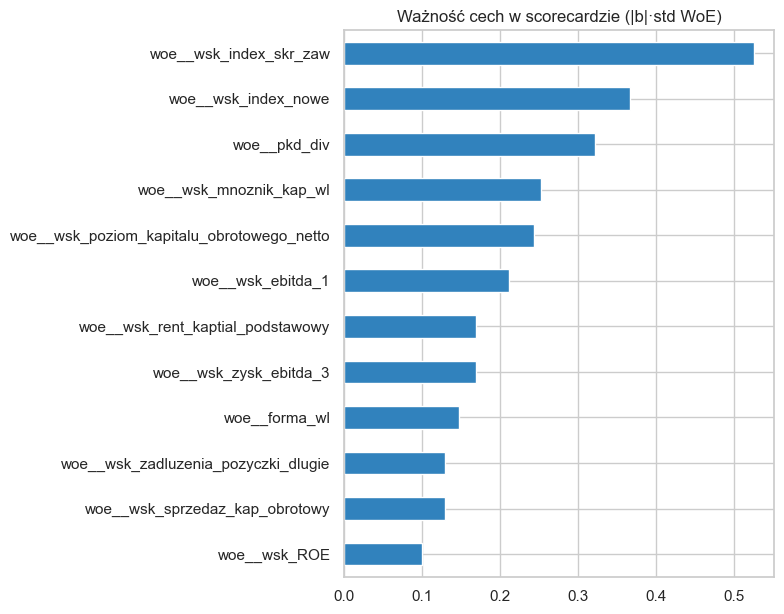

In [8]:
feats_lr = clf_lr.features_
Wtr = prep_lr.transform(Xtr)[feats_lr]
raw_name = lambda f: f.replace("woe__", "", 1)
coef_tab = pd.DataFrame({
    "współczynnik": clf_lr.coef_,
    "odds_ratio_na_1_WoE": np.exp(clf_lr.coef_),
    "std_WoE": Wtr.std().values,
    "ważność |b|·std": np.abs(clf_lr.coef_) * Wtr.std().values,
    "VIF": vif_series(Wtr).values,
    "IV": [prep_lr.iv_table_.loc[raw_name(f), "IV"] for f in feats_lr],
    "kierunek (rosnąca wartość cechy)": [prep_lr.iv_table_.loc[raw_name(f), "kierunek"] for f in feats_lr],
}, index=feats_lr).sort_values("ważność |b|·std", ascending=False)
coef_tab["udział_ważności_%"] = 100 * coef_tab["ważność |b|·std"] / coef_tab["ważność |b|·std"].sum()
print(f"Wyraz wolny: {clf_lr.intercept_:.3f} | wszystkie współczynniki > 0: {bool((clf_lr.coef_ > 0).all())} | max VIF: {coef_tab['VIF'].max():.2f}")
display(coef_tab)

fig, ax = plt.subplots(figsize=(8, 0.4 * len(coef_tab) + 1.5))
coef_tab["ważność |b|·std"][::-1].plot.barh(ax=ax, color="#3182bd"); ax.set_title("Ważność cech w scorecardzie (|b|·std WoE)")
plt.tight_layout(); plt.savefig("figures/lr_importance.png", dpi=150); plt.show()

**Znak vs kierunek zależności.** Kolumna „kierunek" mówi, jak zmienia się ryzyko wraz ze wzrostem wartości *oryginalnej* cechy (`inc` – rośnie, `dec` – maleje). Jest ona wyznaczana z danych (kierunek monotonicznego binningu), więc sama w sobie **nie potwierdza** sensu ekonomicznego – trzeba ją skonfrontować z oczekiwaniem. Robimy to poniżej heurystycznie (słownik słów kluczowych) – **tabelę należy przejrzeć ręcznie**, a nieoczywiste przypadki skomentować w raporcie.

In [9]:
RISK_UP = ("zadluz", "zobowiaz", "dzwigni", "koszt", "udzial_zob", "cykl", "zob_", "mnoznik", "kap_obcego", "zast_kapitalu_obcego")
RISK_DOWN = ("rent", "roa", "roe", "ros", "marza", "ebit", "zysk", "plynnosc", "pokryci", "kapital_wlasn", "udzial_kap", "kapital_do_aktywa",
             "akt_generowania", "dni_istnienia", "log_aktywa", "struktura_kap_wlasnego", "zast_kapitalu_wlasnego", "zwrot")
def expected_direction(name):
    n = name.lower()
    if any(k in n for k in ("koszty_przychody", "koszt_dlugu")): return "inc"
    up, down = any(k in n for k in RISK_UP), any(k in n for k in RISK_DOWN)
    return "inc" if up and not down else "dec" if down and not up else "do oceny"

num_feats = [raw_name(f) for f in feats_lr if raw_name(f) in NUM_INTERP]
econ = pd.DataFrame({"obserwowany_kierunek": [prep_lr.iv_table_.loc[f, "kierunek"] for f in num_feats],
                     "oczekiwany_(heurystyka)": [expected_direction(f) for f in num_feats],
                     "w_słowniku_opisanych": [f not in SUSPICIOUS for f in num_feats]}, index=num_feats)
econ["zgodny?"] = np.where(econ["oczekiwany_(heurystyka)"] == "do oceny", "ręcznie", np.where(econ.obserwowany_kierunek == econ["oczekiwany_(heurystyka)"], "TAK", "NIE – sprawdź"))
display(econ)

,obserwowany_kierunek,oczekiwany_(heurystyka),w_słowniku_opisanych,zgodny?
wsk_index_skr_zaw,inc,do oceny,False,ręcznie
wsk_index_nowe,inc,do oceny,False,ręcznie
wsk_mnoznik_kap_wl,inc,inc,True,TAK
wsk_poziom_kapitalu_obrotowego_netto,dec,do oceny,True,ręcznie
wsk_ebitda_1,dec,dec,True,TAK
wsk_ROE,dec,dec,True,TAK
wsk_rent_kaptial_podstawowy,dec,dec,True,TAK
wsk_sprzedaz_kap_obrotowy,dec,do oceny,True,ręcznie
wsk_zysk_ebitda_3,dec,dec,True,TAK
wsk_zadluzenia_pozyczki_dlugie,inc,inc,True,TAK


In [10]:
# Test monotoniczności poza próbą: biny z train zastosowane do VALIDATION (rzadkie defaulty => szum; patrzymy na zgodność znaku)
Zva = prep_lr.cleaner_.transform(Xva[prep_lr.num_cols]); rows = []
for f in num_feats:
    b = prep_lr.encoder_.bins_[f]; v = Zva[f].values; ok = ~np.isnan(v)
    bi = np.searchsorted(b["edges"], v[ok], side="right")
    t = pd.DataFrame({"bin": bi, "y": yva[ok]}).groupby("bin")["y"].mean()
    rho = spearmanr(t.index, t.values)[0] if len(t) > 2 else np.nan
    expected = 1 if b["direction"] == "inc" else -1
    rows.append(dict(cecha=f, n_binów=len(t), spearman_bin_vs_default_val=rho, zgodny_znak=bool(np.sign(rho) == expected) if not np.isnan(rho) else None))
mono_val = pd.DataFrame(rows).set_index("cecha"); display(mono_val)
print(f"Zgodny znak na walidacji: {mono_val['zgodny_znak'].mean():.0%} cech (na train monotoniczność jest wymuszona z konstrukcji).")

,n_binów,spearman_bin_vs_default_val,zgodny_znak
cecha,,,
wsk_index_skr_zaw,6,0.9429,True
wsk_index_nowe,8,0.5714,True
wsk_mnoznik_kap_wl,5,0.6000,True
wsk_poziom_kapitalu_obrotowego_netto,8,-0.5714,True
wsk_ebitda_1,8,-0.8095,True
wsk_ROE,3,-1.0000,True
wsk_rent_kaptial_podstawowy,6,-0.6000,True
wsk_sprzedaz_kap_obrotowy,4,-0.8000,True
wsk_zysk_ebitda_3,3,-0.5000,True


Zgodny znak na walidacji: 100% cech (na train monotoniczność jest wymuszona z konstrukcji).


### 1.2 Profile binów (punkty scorecardu) i PDP/ICE

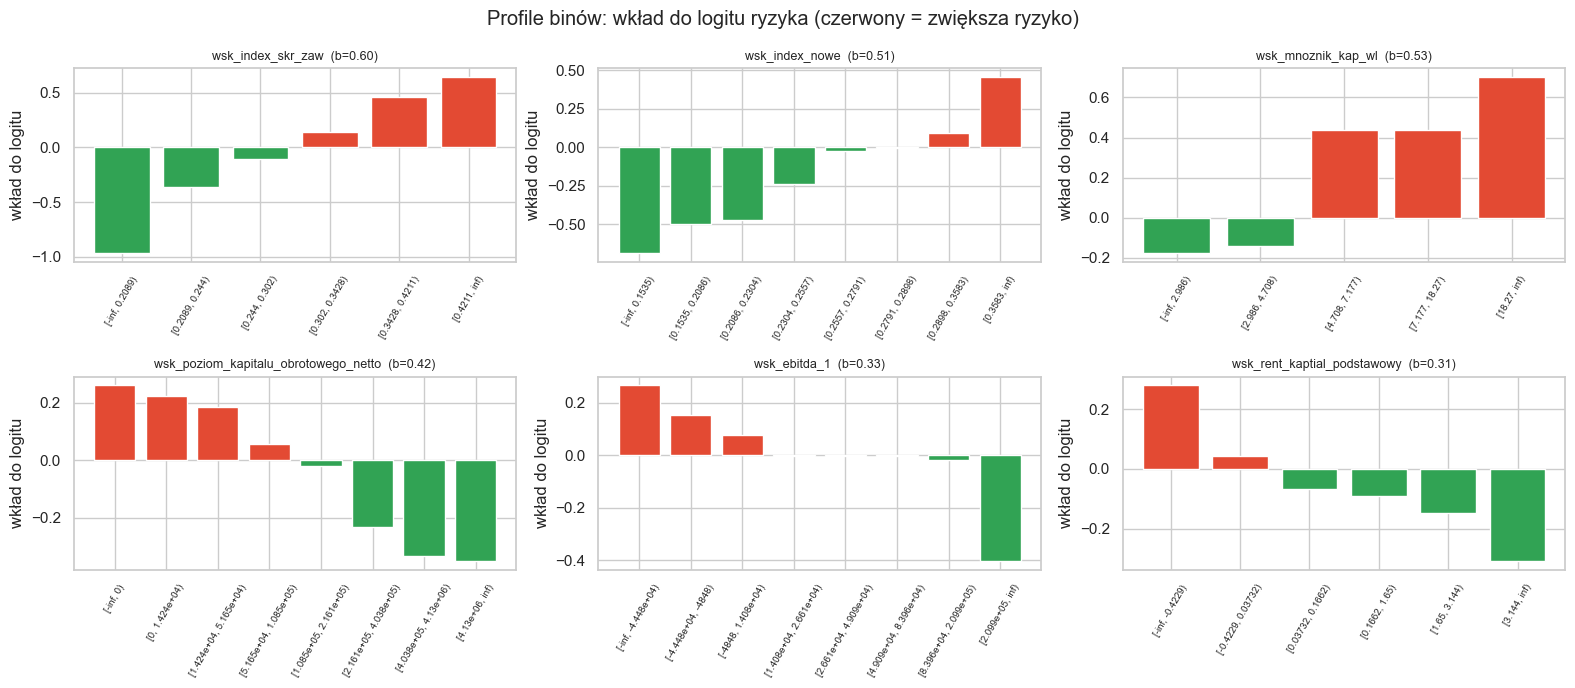

,bin,n,defaulty,default_rate,WoE,wkład_logit
0,"[-inf, 0.2089)",437,5,0.0114,-1.6196,-0.9657
1,"[0.2089, 0.244)",282,9,0.0319,-0.6147,-0.3666
2,"[0.244, 0.302)",359,18,0.0501,-0.1703,-0.1016
3,"[0.302, 0.3428)",353,26,0.0737,0.2309,0.1377
4,"[0.3428, 0.4211)",279,34,0.1219,0.7829,0.4668
5,"[0.4211, inf)",90,14,0.1556,1.0821,0.6452


In [11]:
# wkład binu do logitu = współczynnik · WoE(bin)  (dla najważniejszych cech liczbowych)
top_num = [f for f in coef_tab.index if raw_name(f) in NUM_INTERP][:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, f in zip(axes.ravel(), top_num):
    p = prep_lr.encoder_.profile(raw_name(f)); b = coef_tab.loc[f, "współczynnik"]
    ax.bar(range(len(p)), b * p["WoE"], color=["#e34a33" if v > 0 else "#31a354" for v in b * p["WoE"]])
    ax.set_xticks(range(len(p))); ax.set_xticklabels(p["bin"], rotation=60, fontsize=7)
    ax.set_title(f"{raw_name(f)}  (b={b:.2f})", fontsize=9); ax.set_ylabel("wkład do logitu")
plt.suptitle("Profile binów: wkład do logitu ryzyka (czerwony = zwiększa ryzyko)"); plt.tight_layout(); plt.savefig("figures/lr_bin_profiles.png", dpi=150); plt.show()
display(prep_lr.encoder_.profile(raw_name(top_num[0])).assign(wkład_logit=lambda t: coef_tab.loc[top_num[0], "współczynnik"] * t["WoE"]))

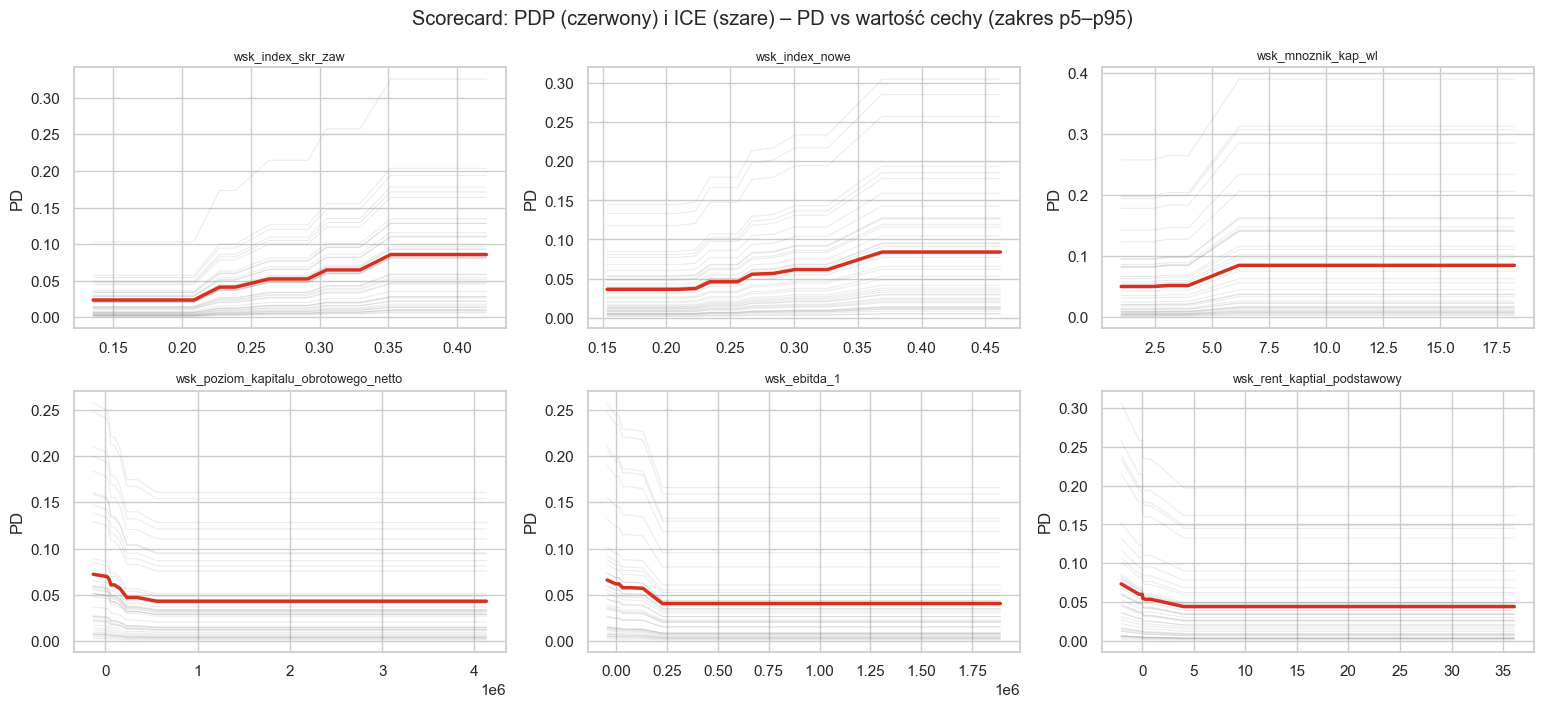

In [12]:
# PDP / ICE liczone ręcznie dla dowolnego pipeline'u (wejście = surowe cechy), więc to samo narzędzie posłuży dla black-box
def pdp_ice(pipe, X, feature, n_grid=15, n_ice=40, qlo=0.05, qhi=0.95, seed=SEED):
    s = X[feature].replace([np.inf, -np.inf], np.nan).dropna()
    grid = np.unique(np.quantile(s, np.linspace(qlo, qhi, n_grid)))
    rng = np.random.default_rng(seed); ice_rows = rng.choice(len(X), min(n_ice, len(X)), replace=False)
    pdp, ice = [], np.zeros((len(ice_rows), len(grid)))
    for j, g in enumerate(grid):
        Xg = X.copy(); Xg[feature] = g
        p = pipe.predict_proba(Xg)[:, 1]; pdp.append(p.mean()); ice[:, j] = p[ice_rows]
    return grid, np.array(pdp), ice

def plot_pdp(pipe, X, features, title, fname=None, ncols=3):
    nrows = int(np.ceil(len(features) / ncols)); fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.6 * nrows)); axes = np.atleast_1d(axes).ravel()
    for ax, f in zip(axes, features):
        g, pdp, ice = pdp_ice(pipe, X, f)
        ax.plot(g, ice.T, color="grey", alpha=.15, lw=.8); ax.plot(g, pdp, color="#d7301f", lw=2.5, label="PDP"); ax.set_title(f, fontsize=9); ax.set_ylabel("PD")
    for ax in axes[len(features):]: ax.axis("off")
    plt.suptitle(title); plt.tight_layout()
    if fname: plt.savefig(fname, dpi=150)
    plt.show()

pdp_feats = [raw_name(f) for f in top_num[:6]]
plot_pdp(pipe_lr, Xtr, pdp_feats, "Scorecard: PDP (czerwony) i ICE (szare) – PD vs wartość cechy (zakres p5–p95)", "figures/lr_pdp.png")

### 1.3 Interpretacja lokalna: dekompozycja logitu na wkłady cech

Dla scorecardu wyjaśnienie jest **dokładne**: logit(PD) = b₀ + Σ bⱼ·WoEⱼ. Wkład cechy względem „przeciętnego klienta” = bⱼ·(WoEⱼ(x) − średnie WoEⱼ w train); suma wkładów + logit przeciętnego klienta = logit(PD) obserwacji (tożsamość sprawdzamy).

In [13]:
W_mean = Wtr.mean()
logit_avg = clf_lr.intercept_ + float((clf_lr.coef_ * W_mean.values).sum())
def lr_contrib(X_rows):
    W = prep_lr.transform(X_rows)[feats_lr]
    return (W - W_mean) * clf_lr.coef_            # DataFrame: wkład każdej cechy w logit względem przeciętnego klienta

# sprawdzenie tożsamości na walidacji
C = lr_contrib(Xva); recon = logit_avg + C.sum(axis=1).values
assert np.allclose(expit(recon), p_val_lr, atol=1e-8), "dekompozycja niezgodna z predykcją"
print("OK: wkłady cech sumują się dokładnie do logitu predykcji scorecardu.")

OK: wkłady cech sumują się dokładnie do logitu predykcji scorecardu.


### 1.4 Stabilność modelu interpretowalnego (CV)

In [14]:
# (a) stabilność metryk – patrz tabela CV powyżej; (b) stabilność selekcji i znaków współczynników w foldach
sel_freq = pd.Series({f: sum(f in m.features_ for m in fold_models_lr) for f in feats_lr})
coefs_cv = pd.DataFrame([pd.Series(m.coef_, m.features_) for m in fold_models_lr]).reindex(columns=feats_lr)
stab = pd.DataFrame({"wybrana_w_foldach": sel_freq, "współczynnik_śr": coefs_cv.mean(), "współczynnik_std": coefs_cv.std(),
                     "CV_współczynnika": coefs_cv.std() / coefs_cv.mean().abs()}).sort_values("wybrana_w_foldach", ascending=False)
display(stab)
sets = [set(m.features_) for m in fold_models_lr]
jac = np.mean([len(a & b) / len(a | b) for a, b in combinations(sets, 2)])
print(f"Średni Jaccard zbiorów cech między foldami: {jac:.2f} | cech wybranych w 5/5 foldów spośród końcowych: {(sel_freq == len(fold_models_lr)).sum()}/{len(feats_lr)}")
print("VIF (końcowy model), max:", round(coef_tab['VIF'].max(), 2), "| złożoność: liczba cech =", len(feats_lr), ", wszystkie ograniczone monotonicznie (biny) i ze znakiem dodatnim")

,wybrana_w_foldach,współczynnik_śr,współczynnik_std,CV_współczynnika
woe__wsk_index_skr_zaw,5,0.5773,0.0506,0.0877
woe__wsk_index_nowe,5,0.5038,0.0604,0.1198
woe__wsk_poziom_kapitalu_obrotowego_netto,5,0.4192,0.0992,0.2366
woe__pkd_div,4,0.5360,0.0362,0.0675
woe__wsk_zysk_ebitda_3,3,0.3979,0.0941,0.2365
woe__wsk_zadluzenia_pozyczki_dlugie,2,0.3766,0.0936,0.2486
woe__wsk_ROE,2,0.3481,0.2386,0.6854
woe__wsk_rent_kaptial_podstawowy,2,0.3351,0.0411,0.1227
woe__forma_wl,2,0.5269,0.0046,0.0086
woe__wsk_sprzedaz_kap_obrotowy,1,0.3571,NaN,NaN


Średni Jaccard zbiorów cech między foldami: 0.32 | cech wybranych w 5/5 foldów spośród końcowych: 3/12
VIF (końcowy model), max: 3.0 | złożoność: liczba cech = 12 , wszystkie ograniczone monotonicznie (biny) i ze znakiem dodatnim


**Do opisania w raporcie (3.3):** (1) 5–10 najważniejszych cech z tabeli ważności, kierunek wpływu i zgodność z intuicją ekonomiczną (tabela „zgodny?" + ręczna weryfikacja); (2) cechy wybierane niestabilnie w foldach (niska `wybrana_w_foldach`) – uczciwie zaznacz, że wybór jednej z grupy silnie skorelowanych wskaźników bywa arbitralny; (3) ewentualne niezgodności ekonomiczne, w szczególności dla zmiennych spoza opisu (`wsk_index_*`).

## 2. Model black-box (3.4): LightGBM

* Wejście: `ScoringFeatureBuilder(mode="blackbox")` – wskaźniki, kwoty w `signed_log1p`, kategorie jako one-hot, winsoryzacja i imputacja mediany (parametry z foldu treningowego).
* **Brak oversamplingu i `scale_pos_weight`** – prawdopodobieństwa nie są sztucznie przesuwane (ważne dla kalibracji w sekcji 5).
* **Tuning:** Random Search (40 konfiguracji) w tym samym Stratified 5-fold CV co model interpretowalny; kryterium = średni log-loss w CV (miara wrażliwa na jakość prawdopodobieństw). Kontrola overfittingu: silna regularyzacja w przestrzeni poszukiwań (małe drzewa, duże `min_child_samples`, L1/L2, subsampling), reguła 1-SE (najprostszy model w obrębie błędu standardowego od najlepszego) oraz raport różnicy AUC train vs CV vs validation.

In [15]:
N_ITER, N_JOBS = 40, 2
folds_bb = prep_folds(FB_BB)
space = dict(n_estimators=randint(100, 501), learning_rate=loguniform(0.01, 0.1), num_leaves=randint(4, 25), max_depth=[-1, 3, 4, 5],
             min_child_samples=randint(20, 81), subsample=uniform(0.6, 0.4), colsample_bytree=uniform(0.4, 0.6),
             reg_lambda=loguniform(0.1, 50), reg_alpha=loguniform(1e-3, 5))
cands = list(ParameterSampler(space, n_iter=N_ITER, random_state=SEED))
mk_lgb = lambda p: lgb.LGBMClassifier(**p, subsample_freq=1, random_state=SEED, n_jobs=N_JOBS, verbose=-1)

rows = []
for k, c in enumerate(cands):
    ll, auc, auc_tr = [], [], []
    for Xa, ya, Xb, yb, _, _ in folds_bb:
        m = mk_lgb(c).fit(Xa, ya); p = m.predict_proba(Xb)[:, 1]
        ll.append(log_loss(yb, p)); auc.append(roc_auc_score(yb, p)); auc_tr.append(roc_auc_score(ya, m.predict_proba(Xa)[:, 1]))
    rows.append(dict(id=k, **c, logloss=np.mean(ll), logloss_se=np.std(ll, ddof=1) / np.sqrt(len(ll)),
                     auc_cv=np.mean(auc), auc_std=np.std(auc, ddof=1), auc_train=np.mean(auc_tr)))
cv_bb = pd.DataFrame(rows).sort_values("logloss").reset_index(drop=True)
cv_bb["gap_auc_train_cv"] = cv_bb["auc_train"] - cv_bb["auc_cv"]
cv_bb["zlozonosc"] = cv_bb["n_estimators"] * cv_bb["num_leaves"]
b0 = cv_bb.iloc[0]
pick = cv_bb[cv_bb.logloss <= b0.logloss + b0.logloss_se].sort_values("zlozonosc").iloc[0]
PARAM_KEYS = list(space.keys())
BEST_BB = {k: (int(pick[k]) if k in ("n_estimators", "num_leaves", "max_depth", "min_child_samples") else float(pick[k])) for k in PARAM_KEYS}
display(cv_bb[["id", "logloss", "logloss_se", "auc_cv", "auc_std", "auc_train", "gap_auc_train_cv", "n_estimators", "num_leaves", "learning_rate", "min_child_samples"]].head(8))
print("Wybrane hiperparametry (reguła 1-SE):", BEST_BB)

,id,logloss,logloss_se,auc_cv,auc_std,auc_train,gap_auc_train_cv,n_estimators,num_leaves,learning_rate,min_child_samples
0,39,0.1992,0.0077,0.7630,0.0608,0.9573,0.1944,243,16,0.0501,71
1,23,0.1995,0.0088,0.7625,0.0659,0.9611,0.1986,459,4,0.0250,37
2,38,0.1998,0.0057,0.7576,0.0604,0.9397,0.1821,207,8,0.0333,79
3,1,0.1999,0.0064,0.7588,0.0516,0.9744,0.2156,249,24,0.0399,22
4,36,0.2004,0.0054,0.7544,0.0551,0.9575,0.2031,241,15,0.0118,35
5,18,0.2007,0.0075,0.7540,0.0655,0.9536,0.1997,151,15,0.0253,68
6,32,0.2007,0.0079,0.7534,0.0564,0.9579,0.2044,198,4,0.0268,50
7,31,0.2008,0.0056,0.7530,0.0600,0.9699,0.2169,271,17,0.0106,36


Wybrane hiperparametry (reguła 1-SE): {'n_estimators': 134, 'learning_rate': 0.053654503243520245, 'num_leaves': 4, 'max_depth': 5, 'min_child_samples': 41, 'subsample': 0.9395655297064336, 'colsample_bytree': 0.5951099932160482, 'reg_lambda': 41.93935995317989, 'reg_alpha': 0.026087653866092905}


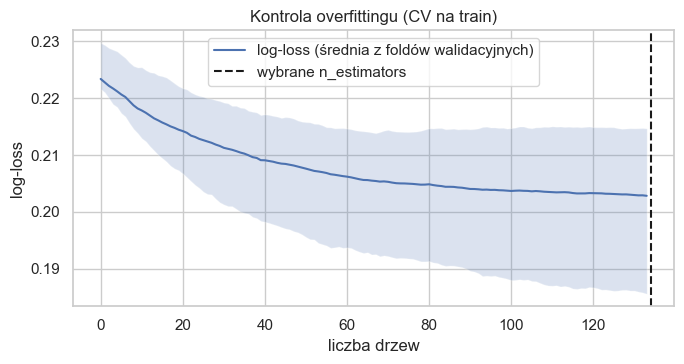

Minimum krzywej przy 134 drzewach; wybrano 134.


In [16]:
# diagnostyka overfittingu: krzywa log-lossu na foldach walidacyjnych w funkcji liczby drzew (dla wybranych hiperparametrów)
curves = []
for Xa, ya, Xb, yb, _, _ in folds_bb:
    m = mk_lgb(BEST_BB).fit(Xa, ya, eval_set=[(Xb, yb)])
    curves.append(np.array(m.evals_result_["valid_0"]["binary_logloss"]))
curves = np.array(curves); mean_c = curves.mean(0)
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.plot(mean_c, label="log-loss (średnia z foldów walidacyjnych)")
ax.fill_between(range(len(mean_c)), curves.min(0), curves.max(0), alpha=.2); ax.axvline(BEST_BB["n_estimators"], color="k", ls="--", label="wybrane n_estimators")
ax.set_xlabel("liczba drzew"); ax.set_ylabel("log-loss"); ax.legend(); ax.set_title("Kontrola overfittingu (CV na train)"); plt.tight_layout(); plt.savefig("figures/bb_overfit_curve.png", dpi=150); plt.show()
print(f"Minimum krzywej przy {int(mean_c.argmin()) + 1} drzewach; wybrano {BEST_BB['n_estimators']}.")

In [17]:
pipe_bb = Pipeline([("prep", ScoringFeatureBuilder(**FB_BB)), ("clf", mk_lgb(BEST_BB))]).fit(Xtr, ytr)
prep_bb, bb_model = pipe_bb.named_steps["prep"], pipe_bb.named_steps["clf"]
oof_bb = pd.Series(index=idx_train, dtype=float); cv_rows_bb = []
for Xa, ya, Xb, yb, tr, va in folds_bb:
    p = mk_lgb(BEST_BB).fit(Xa, ya).predict_proba(Xb)[:, 1]; oof_bb.loc[va] = p; cv_rows_bb.append(all_metrics(yb, p))
p_val_bb = pipe_bb.predict_proba(Xva)[:, 1]; p_tr_bb = pipe_bb.predict_proba(Xtr)[:, 1]

display(pd.concat({"LightGBM – CV (5 foldów)": summarize_cv(cv_rows_bb)[cols]}).round(4))
display(pd.DataFrame({"train (in-sample)": all_metrics(ytr, p_tr_bb), "OOF-CV (train)": all_metrics(ytr, oof_bb.loc[idx_train].values),
                      "validation": all_metrics(yva, p_val_bb)}).T[cols + ["obs_rate"]])
print(f"Liczba cech wejściowych: {len(prep_bb.feature_names_)}")

AUC  PR_AUC     KS  LogLoss  Brier    CITL  Slope  mean_PD
LightGBM – CV (5 foldów) średnia  0.7458  0.1865 0.4338   0.2028 0.0528  0.0434 1.1524   0.0567
                         odch.std 0.0625  0.0639 0.1192   0.0118 0.0020  0.0586 0.5046   0.0022
                         min      0.6939  0.1269 0.3082   0.1856 0.0499 -0.0349 0.7769   0.0545
                         max      0.8382  0.2937 0.5655   0.2147 0.0552  0.1263 1.9874   0.0602

,AUC,PR_AUC,KS,LogLoss,Brier,CITL,Slope,mean_PD,obs_rate
train (in-sample),0.8853,0.4410,0.5946,0.1709,0.0470,0.0236,2.1101,0.0577,0.0589
OOF-CV (train),0.7411,0.1540,0.3817,0.2028,0.0528,0.0429,1.0508,0.0567,0.0589
validation,0.7513,0.2696,0.3712,0.1994,0.0517,0.0613,1.1787,0.0568,0.0600


Liczba cech wejściowych: 237


### 2.1 Wyjaśnialność globalna: SHAP (summary, beeswarm, dependence)
Wyjaśnienia liczymy na zbiorze **walidacyjnym** (nie na teście). Wartości SHAP są w skali log-odds. Uwaga: przy silnie skorelowanych wskaźnikach SHAP „dzieli" wpływ między cechy-bliźniaki (patrz sekcja 3).

,mean|SHAP| (log-odds)
wsk_index_nowe,0.2822
wsk_index_skr_zaw,0.2647
slog_Kapital_wlasny,0.2253
wsk_zysk_ebitda_3,0.0808
wsk_poziom_kapitalu_obrotowego_netto,0.0721
slog_zysk_sprzedazy,0.0645
wsk_struktura_kap_wlasnego_s_2,0.0508
wsk_sprzedaz_kap_obrotowy,0.0375
wsk_zadluzenie_kap_wlasnego,0.0360
wsk_ebitda_zobowiazan_odsetki_4,0.0357


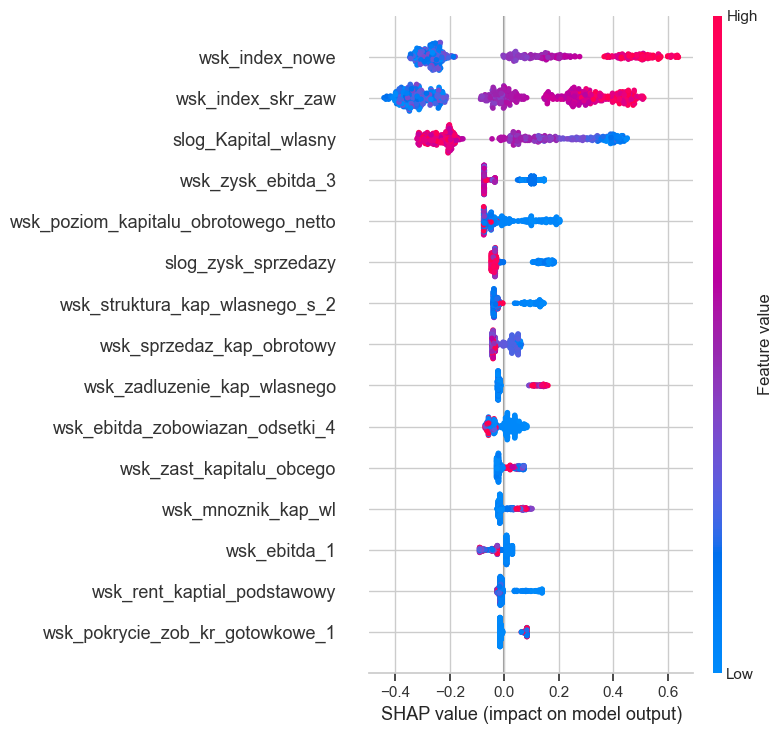

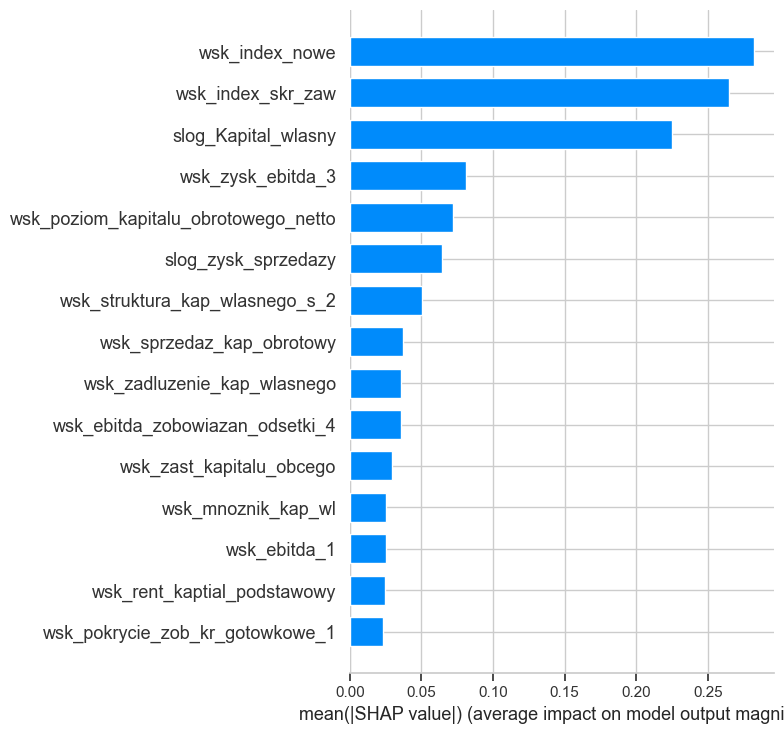

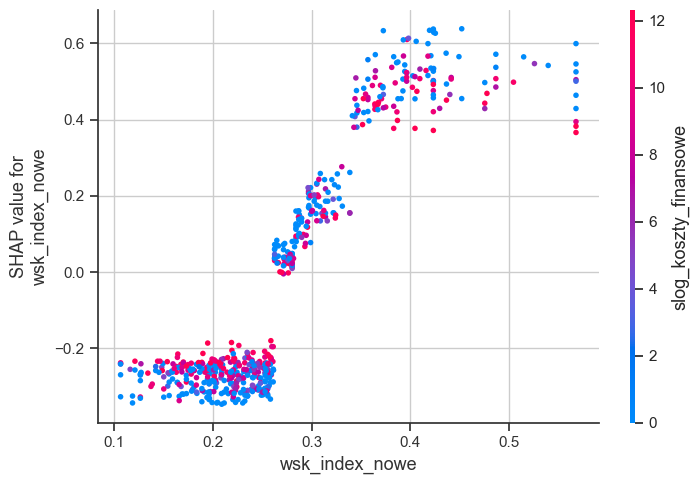

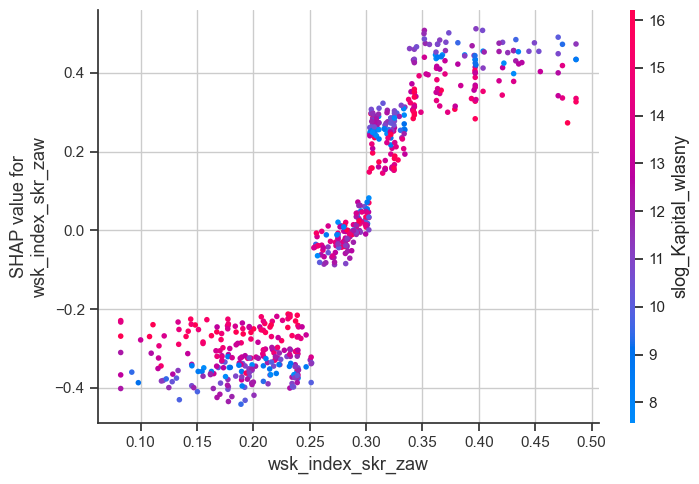

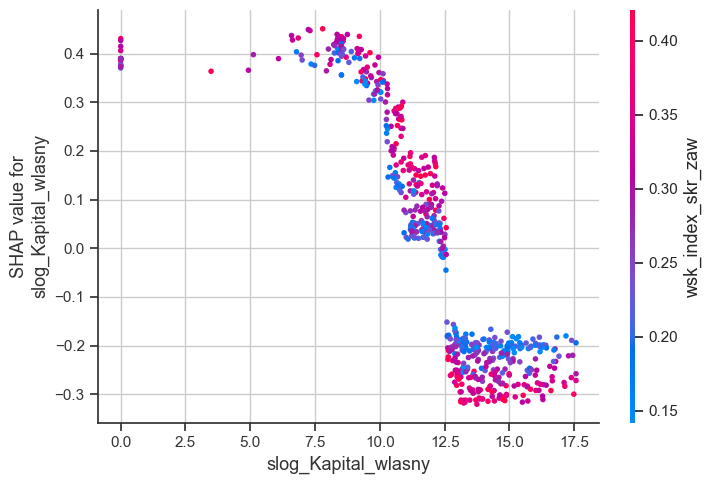

In [18]:
Xbb_tr, Xbb_va = prep_bb.transform(Xtr), prep_bb.transform(Xva)
bb_cols = list(Xbb_tr.columns)
explainer = shap.TreeExplainer(bb_model)

def shap_pos(expl, X):
    sv = expl.shap_values(X)
    if isinstance(sv, list): sv = sv[-1]
    sv = np.asarray(sv)
    if sv.ndim == 3: sv = sv[:, :, -1]
    ev = float(np.atleast_1d(expl.expected_value)[-1])
    return sv, ev

sv_va, ev_va = shap_pos(explainer, Xbb_va)
imp_shap = pd.Series(np.abs(sv_va).mean(0), index=bb_cols).sort_values(ascending=False)
display(imp_shap.head(15).to_frame("mean|SHAP| (log-odds)"))

shap.summary_plot(sv_va, Xbb_va, max_display=15, show=False); plt.tight_layout(); plt.savefig("figures/shap_beeswarm.png", dpi=150); plt.show()
shap.summary_plot(sv_va, Xbb_va, plot_type="bar", max_display=15, show=False); plt.tight_layout(); plt.savefig("figures/shap_bar.png", dpi=150); plt.show()
for f in imp_shap.index[:3]:
    shap.dependence_plot(f, sv_va, Xbb_va, show=False); plt.tight_layout(); plt.savefig(f"figures/shap_dep_{f}.png", dpi=150); plt.show()

### 2.2 PDP/ICE black-boxa oraz porównanie z modelem interpretowalnym

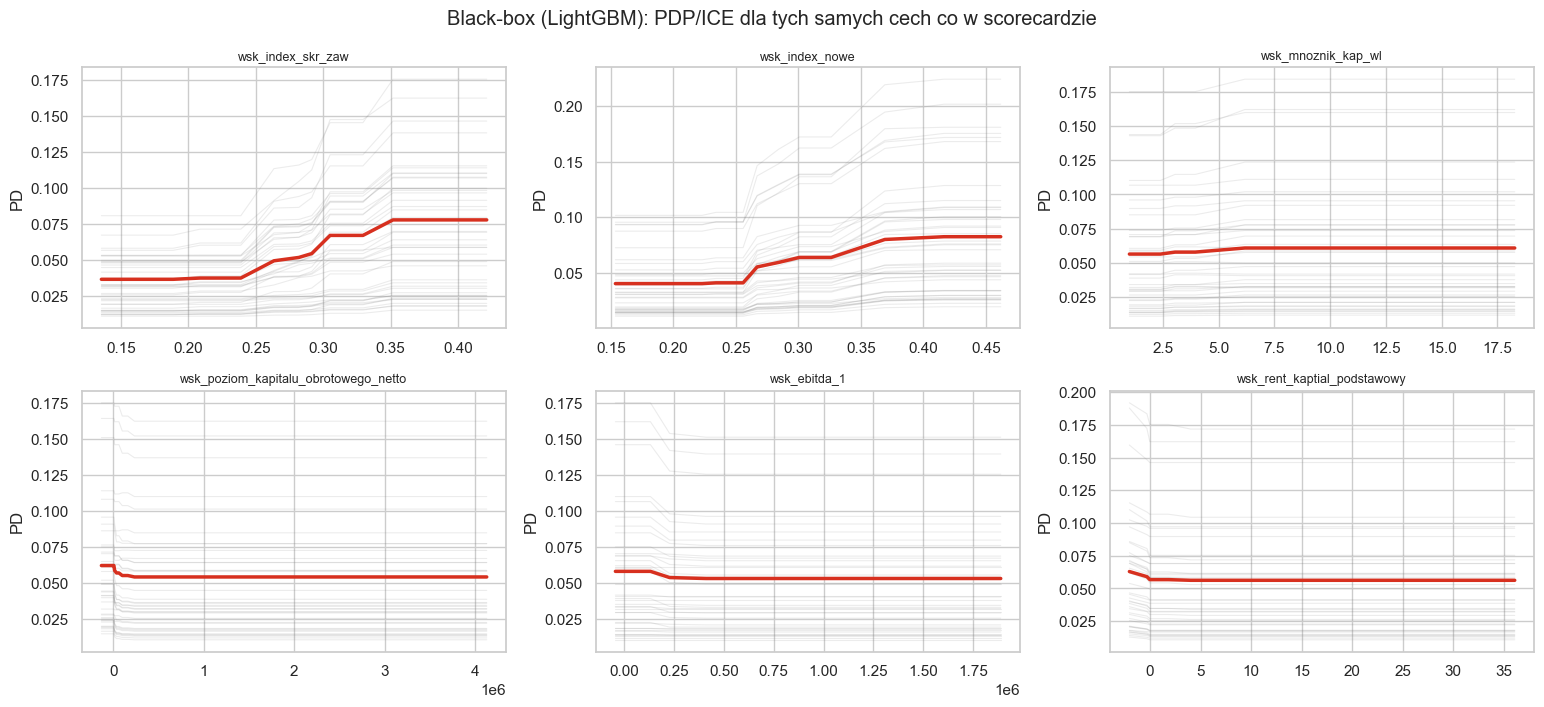

In [19]:
common_pdp = [f for f in pdp_feats if f in NUM_BLACK]
plot_pdp(pipe_bb, Xtr, common_pdp, "Black-box (LightGBM): PDP/ICE dla tych samych cech co w scorecardzie", "figures/bb_pdp.png")

In [20]:
# porównanie globalnych rankingów ważności: scorecard (|b|·std) vs SHAP (mean|SHAP|) – na cechach scorecardu obecnych w macierzy black-box
lr_imp = coef_tab["ważność |b|·std"].rename(index=raw_name)
common = [f for f in lr_imp.index if f in imp_shap.index]
cmp_imp = pd.DataFrame({"scorecard_ważność": lr_imp.loc[common], "SHAP_ważność": imp_shap.loc[common]})
cmp_imp["ranga_scorecard"] = cmp_imp["scorecard_ważność"].rank(ascending=False); cmp_imp["ranga_SHAP"] = cmp_imp["SHAP_ważność"].rank(ascending=False)
display(cmp_imp.sort_values("ranga_scorecard"))
rho = spearmanr(cmp_imp["ranga_scorecard"], cmp_imp["ranga_SHAP"])[0]
k = 5; jacc = len(set(lr_imp.head(k).index) & set(imp_shap.head(k).index)) / len(set(lr_imp.head(k).index) | set(imp_shap.head(k).index))
print(f"Spearman rang (cechy scorecardu obecne w obu modelach, n={len(common)}): {rho:.2f} | Jaccard Top-{k} scorecard vs SHAP: {jacc:.2f}")
print("Top-5 SHAP:", imp_shap.head(5).index.tolist()); print("Top-5 scorecard:", lr_imp.head(5).index.tolist())

,scorecard_ważność,SHAP_ważność,ranga_scorecard,ranga_SHAP
wsk_index_skr_zaw,0.5248,0.2647,1.0000,2.0000
wsk_index_nowe,0.3660,0.2822,2.0000,1.0000
wsk_mnoznik_kap_wl,0.2530,0.0255,3.0000,6.0000
wsk_poziom_kapitalu_obrotowego_netto,0.2433,0.0721,4.0000,4.0000
wsk_ebitda_1,0.2120,0.0251,5.0000,7.0000
wsk_rent_kaptial_podstawowy,0.1694,0.0245,6.0000,8.0000
wsk_zysk_ebitda_3,0.1691,0.0808,7.0000,3.0000
wsk_zadluzenia_pozyczki_dlugie,0.1297,0.0000,8.0000,9.5000
wsk_sprzedaz_kap_obrotowy,0.1295,0.0375,9.0000,5.0000
wsk_ROE,0.0998,0.0000,10.0000,9.5000


Spearman rang (cechy scorecardu obecne w obu modelach, n=10): 0.67 | Jaccard Top-5 scorecard vs SHAP: 0.43
Top-5 SHAP: ['wsk_index_nowe', 'wsk_index_skr_zaw', 'slog_Kapital_wlasny', 'wsk_zysk_ebitda_3', 'wsk_poziom_kapitalu_obrotowego_netto']
Top-5 scorecard: ['wsk_index_skr_zaw', 'wsk_index_nowe', 'pkd_div', 'wsk_mnoznik_kap_wl', 'wsk_poziom_kapitalu_obrotowego_netto']


### 2.3 Interpretacja lokalna: studia przypadków (walidacja)

Wybieramy 4 obserwacje: (1) *default o najwyższym PD*, (2) *dobry klient o najniższym PD*, (3) *przypadek graniczny* – obserwacja o PD z okolic 85. percentyla (granica „15% najgorszych"; po wyznaczeniu progu w 3.6 można ją podmienić) i (4) *niewykryty default* (default o najniższym PD z black-boxa). Dla każdej: wyjaśnienie bezpośrednie scorecardu, SHAP i LIME.

In [21]:
yv = yva; pv_b, pv_l = p_val_bb, p_val_lr
q85 = np.quantile(pv_b, 0.85)
cases = {"1. wykryty default": int(np.where(yv == 1)[0][np.argmax(pv_b[yv == 1])]),
         "2. pewny dobry klient": int(np.where(yv == 0)[0][np.argmin(pv_b[yv == 0])]),
         "3. przypadek graniczny": int(np.argmin(np.abs(pv_b - q85))),
         "4. niewykryty default": int(np.where(yv == 1)[0][np.argmin(pv_b[yv == 1])])}

predict_fn = lambda a: bb_model.predict_proba(pd.DataFrame(a, columns=bb_cols))
bin_idx = [i for i, c in enumerate(bb_cols) if set(np.unique(Xbb_tr[c])) <= {0, 1}]
def make_lime(seed):
    return LimeTabularExplainer(Xbb_tr.values, feature_names=bb_cols, class_names=["non-default", "default"], mode="classification",
                                categorical_features=bin_idx, discretize_continuous=True, random_state=seed)
def lime_score(e):                         # w zależności od wersji lime score/local_pred są liczbą albo słownikiem {etykieta: wartość}
    s = e.score; return float(s[1] if isinstance(s, dict) else s)
def lime_local_pred(e):
    lp = e.local_pred; lp = lp[1] if isinstance(lp, dict) else lp; return float(np.atleast_1d(lp)[0])
def lime_explain(i, seed=0, k=10, n=5000):
    return make_lime(seed).explain_instance(Xbb_va.iloc[i].values, predict_fn, num_features=k, num_samples=n)

def case_table(name, i, k=5):
    c = lr_contrib(Xva.iloc[[i]]).iloc[0]; c.index = [raw_name(f) for f in c.index]
    e = lime_explain(i, seed=SEED); lw = pd.Series({bb_cols[j]: w for j, w in e.local_exp[1]})
    s = pd.Series(sv_va[i], index=bb_cols)
    top = lambda ser: ", ".join(f"{n} ({v:+.2f})" for n, v in ser.reindex(ser.abs().sort_values(ascending=False).index).head(k).items())
    print(f"=== {name} | y={yv[i]} | PD scorecard={pv_l[i]:.3f}, PD LightGBM={pv_b[i]:.3f} | LIME R^2={lime_score(e):.2f}")
    print("  scorecard (wkład w logit):", top(c)); print("  SHAP (log-odds):          ", top(s)); print("  LIME (waga lokalna):      ", top(lw)); print()

for name, i in cases.items():
    case_table(name, i)

=== 1. wykryty default | y=1 | PD scorecard=0.513, PD LightGBM=0.310 | LIME R^2=0.46
  scorecard (wkład w logit): wsk_index_skr_zaw (+0.65), pkd_div (+0.62), wsk_index_nowe (+0.57), wsk_zadluzenia_pozyczki_dlugie (+0.56), wsk_mnoznik_kap_wl (+0.50)
  SHAP (log-odds):           wsk_index_nowe (+0.52), wsk_index_skr_zaw (+0.48), slog_Kapital_wlasny (+0.20), slog_zysk_sprzedazy (+0.16), wsk_zadluzenie_kap_wlasnego (+0.14)
  LIME (waga lokalna):       wsk_index_nowe (+0.03), wsk_index_skr_zaw (+0.03), wsk_zadluzenie_kap_wlasnego (+0.01), slog_Zobowiazania_dostaw_uslug_pow12m_pozostale (-0.01), slog_zysk_sprzedazy (+0.01)

=== 2. pewny dobry klient | y=0 | PD scorecard=0.003, PD LightGBM=0.011 | LIME R^2=0.22
  scorecard (wkład w logit): wsk_index_skr_zaw (-0.79), wsk_index_nowe (-0.57), wsk_poziom_kapitalu_obrotowego_netto (-0.27), pkd_div (-0.16), wsk_zysk_ebitda_3 (-0.13)
  SHAP (log-odds):           wsk_index_skr_zaw (-0.27), wsk_index_nowe (-0.24), slog_Kapital_wlasny (-0.21), wsk_pozi

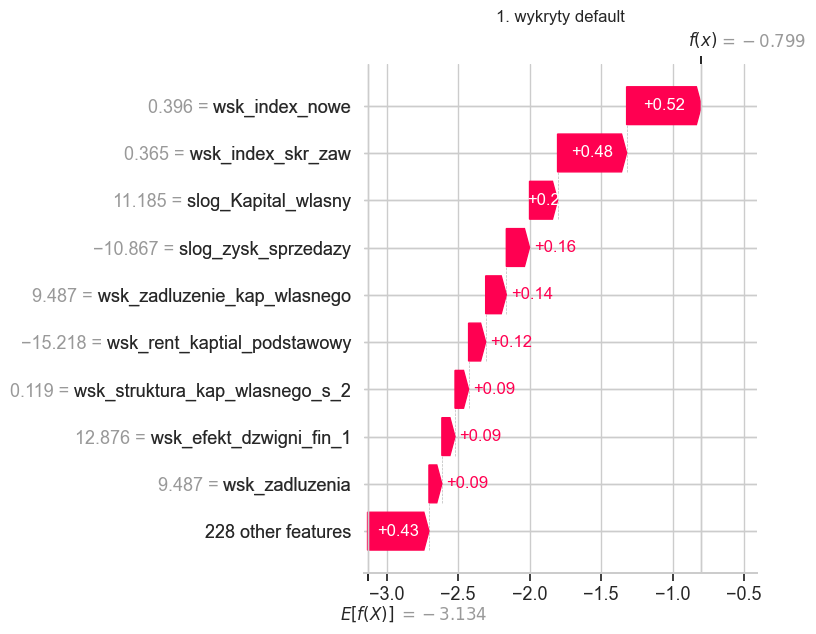

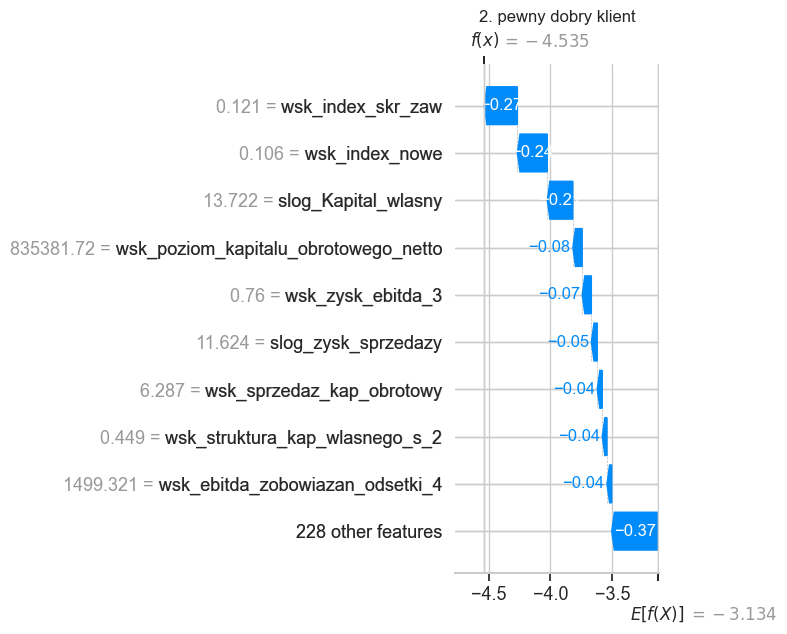

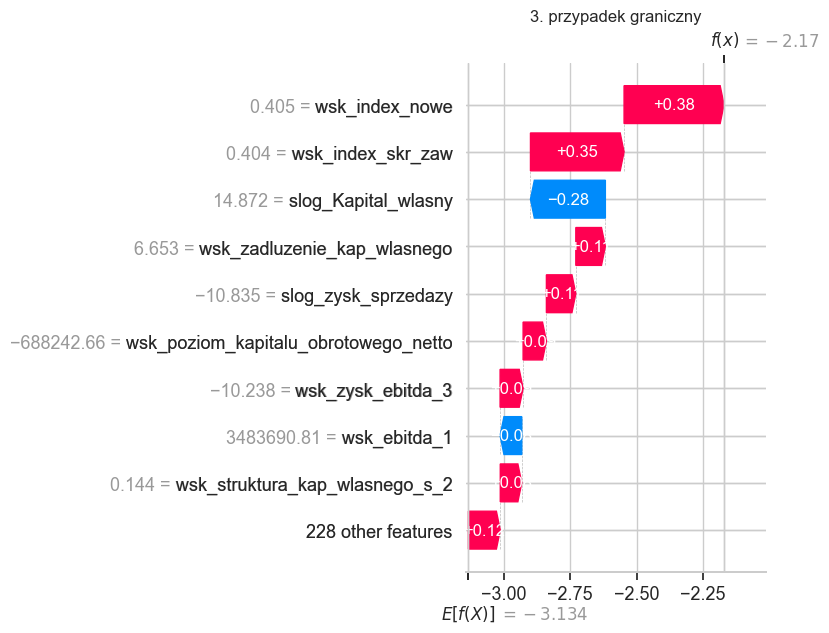

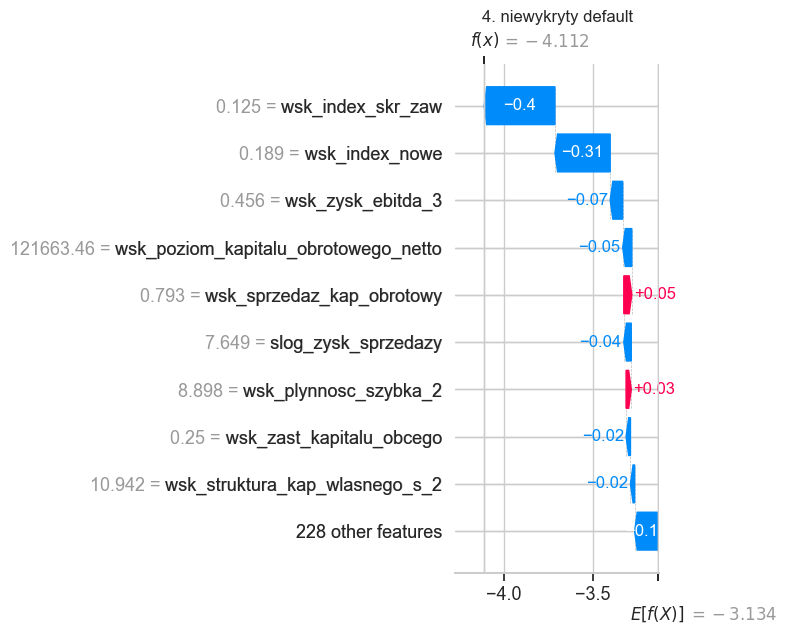

In [22]:
# wykresy SHAP waterfall dla przypadków
for name, i in cases.items():
    shap.plots.waterfall(shap.Explanation(values=sv_va[i], base_values=ev_va, data=Xbb_va.iloc[i].values, feature_names=bb_cols), max_display=10, show=False)
    plt.title(name); plt.tight_layout(); plt.savefig(f"figures/shap_waterfall_{name[:1]}.png", dpi=150); plt.show()

### 2.4 What-if
Dla obserwacji z przypadku 1 (wykryty default): ustawiamy 3 najsilniej *zwiększające ryzyko* (wg SHAP) wskaźniki na medianę z train – pojedynczo i razem – i porównujemy reakcję obu modeli. Zmiany dotyczą surowych cech i przechodzą przez cały pipeline (binning/WoE, imputacja itd.).

In [23]:
i0 = cases["1. wykryty default"]
raw_feats = [f for f in pd.Series(sv_va[i0], index=bb_cols).sort_values(ascending=False).index if f in NUM_INTERP][:3]
med = Xtr[raw_feats].replace([np.inf, -np.inf], np.nan).median()
base = Xva.iloc[[i0]]
scen = {"obserwacja (bez zmian)": {}}; scen.update({f"{f} -> mediana": {f: med[f]} for f in raw_feats}); scen["wszystkie 3 -> mediana"] = {f: med[f] for f in raw_feats}
wi = []
for name, ch in scen.items():
    r = base.copy()
    for f, v in ch.items(): r[f] = v
    wi.append(dict(scenariusz=name, PD_scorecard=pipe_lr.predict_proba(r)[0, 1], PD_LightGBM=pipe_bb.predict_proba(r)[0, 1]))
display(pd.DataFrame(wi)); print("Wartości obserwacji:", base[raw_feats].iloc[0].to_dict(), "| mediany train:", med.to_dict())

,scenariusz,PD_scorecard,PD_LightGBM
0,obserwacja (bez zmian),0.5134,0.3103
1,wsk_index_nowe -> mediana,0.3949,0.1629
2,wsk_index_skr_zaw -> mediana,0.3741,0.2124
3,wsk_zadluzenie_kap_wlasnego -> mediana,0.5134,0.2727
4,wszystkie 3 -> mediana,0.2699,0.0895


Wartości obserwacji: {'wsk_index_nowe': 0.3962252513415165, 'wsk_index_skr_zaw': 0.3653089166524046, 'wsk_zadluzenie_kap_wlasnego': 9.486889178743988} | mediany train: {'wsk_index_nowe': 0.25569526167116297, 'wsk_index_skr_zaw': 0.2819018762382008, 'wsk_zadluzenie_kap_wlasnego': 0.5140819628519139}


## 3. Wierność i stabilność wyjaśnień (eksperymenty obowiązkowe)

### 3.1 Wierność (fidelity)
* **LIME:** lokalne R² modelu zastępczego (ważonego w otoczeniu obserwacji) oraz błąd `|predykcja lokalnego modelu − predykcja black-boxa|` dla 30 losowych obserwacji walidacyjnych.
* **SHAP:** sprawdzenie addytywności – `wartość bazowa + Σ SHAP = surowy wynik (log-odds) modelu`.
* **Scorecard:** wyjaśnienie bezpośrednie jest tożsame z modelem (sprawdzone w 1.3).

,i,R2_lokalne,PD_model,PD_lime,blad_abs
mean,322.6000,0.2574,0.0710,0.0718,0.0246
50%,315.5000,0.2283,0.0603,0.0798,0.0212
min,49.0000,0.0727,0.0130,0.0155,0.0001
max,588.0000,0.5847,0.2083,0.1440,0.0804


LIME: mediana lokalnego R^2 = 0.23; udział obserwacji z R^2<0.5: 97%; mediana błędu |ΔPD| = 0.021
SHAP – maks. błąd addytywności: 5.77e-15 (log-odds)


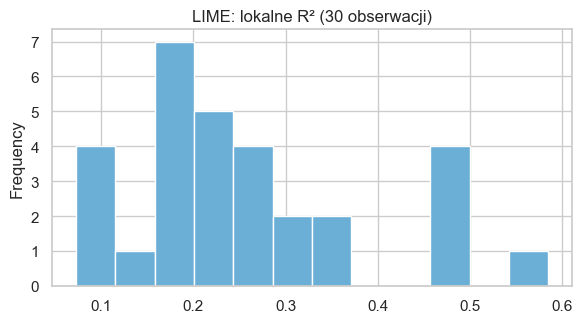

In [24]:
rng = np.random.default_rng(SEED); sample_i = rng.choice(len(Xva), 30, replace=False)
fid = []
for i in sample_i:
    e = lime_explain(int(i), seed=SEED, k=10)
    lp = lime_local_pred(e); mp = float(np.asarray(e.predict_proba)[1])
    fid.append(dict(i=int(i), R2_lokalne=lime_score(e), PD_model=mp, PD_lime=lp, blad_abs=abs(lp - mp)))
fid = pd.DataFrame(fid); display(fid.describe().loc[["mean", "50%", "min", "max"]])
print(f"LIME: mediana lokalnego R^2 = {fid.R2_lokalne.median():.2f}; udział obserwacji z R^2<0.5: {(fid.R2_lokalne < 0.5).mean():.0%}; mediana błędu |ΔPD| = {fid.blad_abs.median():.3f}")
raw_val = bb_model.predict(Xbb_va, raw_score=True)
add_err = np.abs(ev_va + sv_va.sum(1) - raw_val).max()
print(f"SHAP – maks. błąd addytywności: {add_err:.2e} (log-odds)")
fig, ax = plt.subplots(figsize=(6, 3.4)); fid.R2_lokalne.plot.hist(bins=12, ax=ax, color="#6baed6"); ax.set_title("LIME: lokalne R² (30 obserwacji)"); plt.tight_layout(); plt.savefig("figures/lime_fidelity.png", dpi=150); plt.show()

### 3.2 Stabilność
Rozdzielamy trzy źródła niestabilności:
1. **metoda** – ta sama obserwacja i ten sam model, LIME z 10 różnymi seedami (Spearman wag, Jaccard Top-5, zgodność znaku),
2. **próbka objaśniana** – bootstrap wierszy walidacyjnych dla globalnego rankingu SHAP,
3. **model** – przetrenowanie LightGBM na 5 foldach treningowych i porównanie rankingów SHAP (na tym samym zbiorze walidacyjnym); dla porównania ten sam test dla współczynników scorecardu.

In [25]:
def lime_w(i, seed):
    e = lime_explain(i, seed=seed, k=10); w = np.zeros(len(bb_cols))
    for j, v in e.local_exp[1]: w[j] = v
    return w
topk = lambda w, k=5: set(np.argsort(-np.abs(w))[:k])
def pair_stats(W, k=5):
    used = np.where((W != 0).any(0))[0]; sp, jc = [], []
    for a, b in combinations(range(len(W)), 2):
        sp.append(spearmanr(W[a, used], W[b, used])[0]); jc.append(len(topk(W[a], k) & topk(W[b], k)) / len(topk(W[a], k) | topk(W[b], k)))
    return np.nanmean(sp), np.mean(jc)

seeds = list(range(10)); rows = []
for name, i in cases.items():
    W = np.array([lime_w(i, s) for s in seeds]); sp, jc = pair_stats(W)
    top3 = list(np.argsort(-np.abs(W.mean(0)))[:3])
    same_sign = np.mean([np.mean(np.sign(W[:, j]) == np.sign(np.median(W[:, j]))) for j in top3])
    rows.append(dict(przypadek=name, Spearman_wag=sp, Jaccard_top5=jc, zgodność_znaku_top3=same_sign))
lime_stab = pd.DataFrame(rows).set_index("przypadek"); display(lime_stab)

,Spearman_wag,Jaccard_top5,zgodność_znaku_top3
przypadek,,,
1. wykryty default,0.7602,0.7217,1.0000
2. pewny dobry klient,0.4935,0.4656,1.0000
3. przypadek graniczny,0.8705,0.7249,1.0000
4. niewykryty default,0.3870,0.4497,1.0000


In [26]:

# ============================================================
# STABILNOŚĆ WYJAŚNIEŃ SHAP – POPRAWIONY EKSPERYMENT
# ============================================================

from itertools import combinations
from scipy.stats import spearmanr

K = 10

# ------------------------------------------------------------
# Funkcja pomocnicza: Spearman i Jaccard Top-K
# ------------------------------------------------------------
def pairwise_rank_stats(M, k=10):
    """
    M: DataFrame
       Wiersze = cechy, kolumny = rankingi z różnych eksperymentów.
    Brak cechy w danym modelu oznacza importance = 0.
    """
    spearmans = []
    jaccards = []

    for a, b in combinations(M.columns, 2):
        x = M[a]
        y = M[b]

        rho = spearmanr(x, y)[0]
        if np.isfinite(rho):
            spearmans.append(rho)

        top_a = set(x.nlargest(k).index)
        top_b = set(y.nlargest(k).index)

        union = top_a | top_b
        intersection = top_a & top_b

        jaccards.append(len(intersection) / len(union) if union else np.nan)

    return (
        float(np.nanmean(spearmans)),
        float(np.nanmean(jaccards))
    )


# ============================================================
# 1. BOOTSTRAP – TEN SAM MODEL, RÓŻNE PRÓBKI WALIDACYJNE
# ============================================================

B = 200
rng_stab = np.random.default_rng(SEED)

# Referencyjny ranking SHAP z całego validation
full_imp = pd.Series(
    np.abs(sv_va).mean(axis=0),
    index=bb_cols
)

ref_top = set(full_imp.nlargest(K).index)

boot_spearman = []
boot_jaccard = []

boot_top_freq = pd.Series(0.0, index=bb_cols)

for b in range(B):

    # Losowanie obserwacji ze zwracaniem
    sample_idx = rng_stab.integers(0, len(sv_va), size=len(sv_va))

    # Globalna ważność SHAP w wylosowanej próbce
    imp = pd.Series(
        np.abs(sv_va[sample_idx]).mean(axis=0),
        index=bb_cols
    )

    # Porównanie z rankingiem referencyjnym
    rho = spearmanr(full_imp.values, imp.values)[0]
    boot_spearman.append(rho)

    top_b = set(imp.nlargest(K).index)
    boot_jaccard.append(
        len(ref_top & top_b) / len(ref_top | top_b)
    )

    boot_top_freq.loc[list(top_b)] += 1

boot_top_freq /= B

boot_summary = {
    "Spearman_mean": np.mean(boot_spearman),
    "Spearman_5%": np.quantile(boot_spearman, 0.05),
    "Spearman_95%": np.quantile(boot_spearman, 0.95),
    "Jaccard_mean": np.mean(boot_jaccard),
    "Jaccard_5%": np.quantile(boot_jaccard, 0.05),
    "Jaccard_95%": np.quantile(boot_jaccard, 0.95)
}

print("BOOTSTRAP SHAP – stabilność rankingu dla tego samego modelu")
display(pd.Series(boot_summary).to_frame("Wynik"))

print("Najczęściej występujące cechy w Top-10 podczas bootstrapu:")
display(
    boot_top_freq.sort_values(ascending=False)
    .head(15)
    .to_frame("Częstość w Top-10")
)


# ============================================================
# 2. REFIT – NOWY PREPROCESSING I NOWY MODEL W KAŻDYM FOLDZIE
# ============================================================

refit_importances = []

for fold_id, (tr, va) in enumerate(cv_train, start=1):

    # Nowy preprocessing dopasowany WYŁĄCZNIE na foldzie treningowym
    prep_fold = ScoringFeatureBuilder(**FB_BB).fit(
        df.iloc[tr],
        y_all[tr]
    )

    # Transformacja treningu i wspólnego zbioru referencyjnego
    X_fold_tr = prep_fold.transform(df.iloc[tr])
    X_ref = prep_fold.transform(Xva)

    # Nowy model LightGBM
    # Hiperparametry pozostają stałe – badamy wpływ próby i preprocessingu
    model_fold = mk_lgb(BEST_BB).fit(
        X_fold_tr,
        y_all[tr]
    )

    # SHAP na tym samym zbiorze surowych obserwacji validation
    explainer_fold = shap.TreeExplainer(model_fold)
    sv_fold, _ = shap_pos(explainer_fold, X_ref)

    # Globalna ważność cech dla konkretnego modelu
    imp_fold = pd.Series(
        np.abs(sv_fold).mean(axis=0),
        index=X_ref.columns,
        name=f"fold_{fold_id}"
    )

    refit_importances.append(imp_fold)


# Wspólny zestaw cech – brakująca cecha otrzymuje importance = 0
refit_matrix = pd.concat(
    refit_importances,
    axis=1
).fillna(0.0)

# Porównanie wszystkich par modeli
refit_spearman, refit_jaccard = pairwise_rank_stats(
    refit_matrix,
    k=K
)

# Częstość pojawiania się cech w Top-10 poszczególnych modeli
fold_top_freq = pd.Series(0.0, index=refit_matrix.index)

for col in refit_matrix.columns:
    top = refit_matrix[col].nlargest(K).index
    fold_top_freq.loc[list(top)] += 1 / len(refit_matrix.columns)

print("REFIT SHAP – stabilność między foldami")
print(f"Średni Spearman: {refit_spearman:.4f}")
print(f"Średni Jaccard Top-{K}: {refit_jaccard:.4f}")

print("Najczęściej występujące cechy w Top-10 między foldami:")
display(
    fold_top_freq.sort_values(ascending=False)
    .head(15)
    .to_frame("Częstość w Top-10")
)


# ============================================================
# 3. STABILNOŚĆ MODELU INTERPRETOWALNEGO – SCORECARD
# ============================================================

lr_cv_imp = []

for model_fold, (Xa, *_rest) in zip(fold_models_lr, folds_woe):

    importance = pd.Series(
        np.abs(model_fold.coef_.ravel()) *
        Xa[model_fold.features_].std().values,
        index=[raw_name(f) for f in model_fold.features_]
    )

    lr_cv_imp.append(importance)

lr_matrix = pd.concat(lr_cv_imp, axis=1).fillna(0.0)

lr_spearman, lr_jaccard = pairwise_rank_stats(
    lr_matrix,
    k=K
)


# ============================================================
# 4. ZBIORCZE PORÓWNANIE
# ============================================================

stab_tab = pd.DataFrame([
    {
        "eksperyment": "SHAP – bootstrap, ten sam model",
        "Spearman": np.mean(boot_spearman),
        "Jaccard Top-10": np.mean(boot_jaccard)
    },
    {
        "eksperyment": "SHAP – refit z preprocessingiem w foldach",
        "Spearman": refit_spearman,
        "Jaccard Top-10": refit_jaccard
    },
    {
        "eksperyment": "Scorecard – refit między foldami",
        "Spearman": lr_spearman,
        "Jaccard Top-10": lr_jaccard
    }
]).set_index("eksperyment")

display(stab_tab)

print(
    f"LIME – zmiana seedu: średni Spearman wag = "
    f"{lime_stab.Spearman_wag.mean():.2f}, "
    f"Jaccard Top-5 = {lime_stab.Jaccard_top5.mean():.2f}"
)


BOOTSTRAP SHAP – stabilność rankingu dla tego samego modelu


,Wynik
Spearman_mean,0.9999
Spearman_5%,0.9999
Spearman_95%,1.0000
Jaccard_mean,1.0000
Jaccard_5%,1.0000
Jaccard_95%,1.0000


Najczęściej występujące cechy w Top-10 podczas bootstrapu:


,Częstość w Top-10
wsk_index_skr_zaw,1.0000
wsk_index_nowe,1.0000
wsk_sprzedaz_kap_obrotowy,1.0000
wsk_ebitda_zobowiazan_odsetki_4,1.0000
wsk_zadluzenie_kap_wlasnego,1.0000
wsk_poziom_kapitalu_obrotowego_netto,1.0000
slog_Kapital_wlasny,1.0000
wsk_struktura_kap_wlasnego_s_2,1.0000
wsk_zysk_ebitda_3,1.0000
slog_zysk_sprzedazy,1.0000


REFIT SHAP – stabilność między foldami
Średni Spearman: 0.5286
Średni Jaccard Top-10: 0.3919
Najczęściej występujące cechy w Top-10 między foldami:


,Częstość w Top-10
wsk_index_skr_zaw,1.0000
wsk_index_nowe,1.0000
slog_Kapital_wlasny,1.0000
wsk_poziom_kapitalu_obrotowego_netto,0.8000
wsk_zast_kapitalu_obcego,0.8000
slog_zysk_sprzedazy,0.8000
wsk_struktura_kap_wlasnego_s_2,0.6000
wsk_zysk_ebitda_3,0.6000
slog_Zobowiazania_rezerwy,0.4000
wsk_sprzedaz_kap_obrotowy,0.4000


,Spearman,Jaccard Top-10
eksperyment,,
"SHAP – bootstrap, ten sam model",0.9999,1.0000
SHAP – refit z preprocessingiem w foldach,0.5286,0.3919
Scorecard – refit między foldami,0.3222,0.3132


LIME – zmiana seedu: średni Spearman wag = 0.63, Jaccard Top-5 = 0.59


### 3.3 Ograniczenia SHAP/LIME w tym zbiorze
Poniżej: (1) korelacje między najważniejszymi cechami SHAP (wpływ „rozmywa się" między bliźniaki, a ranking pojedynczej cechy bywa mylący); (2) przypomnienie, że LIME ma stochastyczne próbkowanie i zależy od dyskretyzacji, a SHAP (TreeSHAP) uwzględnia ścieżki drzew, nie zależności przyczynowe.

In [27]:
top10 = imp_shap.head(10).index
Cc = Xbb_tr[top10].corr(method="spearman").abs(); Cv = Cc.values.copy(); np.fill_diagonal(Cv, 0)
display(pd.DataFrame({"max|rho| z inną cechą z Top-10": Cv.max(1), "najbardziej skorelowana": [top10[j] for j in Cv.argmax(1)]}, index=top10))

,max|rho| z inną cechą z Top-10,najbardziej skorelowana
wsk_index_nowe,0.6465,wsk_index_skr_zaw
wsk_index_skr_zaw,0.6465,wsk_index_nowe
slog_Kapital_wlasny,0.6868,wsk_poziom_kapitalu_obrotowego_netto
wsk_zysk_ebitda_3,0.2015,wsk_sprzedaz_kap_obrotowy
wsk_poziom_kapitalu_obrotowego_netto,0.6868,slog_Kapital_wlasny
slog_zysk_sprzedazy,0.6716,wsk_ebitda_zobowiazan_odsetki_4
wsk_struktura_kap_wlasnego_s_2,0.7156,wsk_zadluzenie_kap_wlasnego
wsk_sprzedaz_kap_obrotowy,0.4496,wsk_poziom_kapitalu_obrotowego_netto
wsk_zadluzenie_kap_wlasnego,0.7156,wsk_struktura_kap_wlasnego_s_2
wsk_ebitda_zobowiazan_odsetki_4,0.6716,slog_zysk_sprzedazy


**Do opisania w raporcie:** czy niestabilność wynika z metody czy z modelu – porównaj wiersze tabeli stabilności: jeśli Spearman/Jaccard dla *przetrenowania* jest wyraźnie niższy niż dla *bootstrapu wierszy*, to większość zmienności pochodzi z samego modelu (mała liczba defaultów, wiele skorelowanych cech); jeśli LIME-seed jest niestabilny przy stabilnym SHAP – to wina metody. Przypadki, w których wyjaśnienia są niepełne/mylące: korelowane bliźniaki (podział wkładu), niskie lokalne R² LIME w pobliżu „załamań" modelu, wyjaśnienia poza zakresem danych (what-if), brak interpretacji przyczynowej.

## 4. Porównanie modeli (walidacja) i zamrożenie

In [28]:
cmp = pd.DataFrame({"Scorecard (WoE+LR)": all_metrics(yva, p_val_lr), "LightGBM": all_metrics(yva, p_val_bb)}).T
cmp["liczba cech"] = [len(feats_lr), len(prep_bb.feature_names_)]
cmp["CV AUC śr±std"] = [f"{np.mean([r['AUC'] for r in cv_rows_lr]):.3f}±{np.std([r['AUC'] for r in cv_rows_lr], ddof=1):.3f}",
                        f"{np.mean([r['AUC'] for r in cv_rows_bb]):.3f}±{np.std([r['AUC'] for r in cv_rows_bb], ddof=1):.3f}"]
cmp["CV LogLoss śr±std"] = [f"{np.mean([r['LogLoss'] for r in cv_rows_lr]):.3f}±{np.std([r['LogLoss'] for r in cv_rows_lr], ddof=1):.3f}",
                            f"{np.mean([r['LogLoss'] for r in cv_rows_bb]):.3f}±{np.std([r['LogLoss'] for r in cv_rows_bb], ddof=1):.3f}"]
display(cmp[["AUC", "PR_AUC", "KS", "LogLoss", "Brier", "CITL", "Slope", "mean_PD", "liczba cech", "CV AUC śr±std", "CV LogLoss śr±std"]])

# istotność różnicy AUC na walidacji – bootstrap (przy ~36 defaultach różnice rzędu 0.02–0.03 mogą być szumem)
rbs = np.random.default_rng(SEED); diffs = []
for _ in range(1000):
    r = rbs.integers(0, len(yva), len(yva))
    if yva[r].min() == yva[r].max(): continue
    diffs.append(roc_auc_score(yva[r], p_val_bb[r]) - roc_auc_score(yva[r], p_val_lr[r]))
print(f"ΔAUC (LightGBM − scorecard) na walidacji: {np.mean(diffs):+.3f}, 95% przedział bootstrap [{np.percentile(diffs, 2.5):+.3f}, {np.percentile(diffs, 97.5):+.3f}]")

FROZEN = {"BEST_LR": BEST_LR, "BEST_BB": BEST_BB, "FB_WOE": {k: v for k, v in FB_WOE.items() if k not in ("num_cols", "cat_cols")},
          "FB_BB": {k: v for k, v in FB_BB.items() if k not in ("num_cols", "cat_cols")}, "features_scorecard": feats_lr}
joblib.dump({"pipe_lr": pipe_lr, "pipe_bb": pipe_bb}, f"{ART}/models_frozen.joblib"); json.dump(FROZEN, open(f"{ART}/models_frozen_params.json", "w"), indent=2, default=float)
print("Modele zamrożone – od tej chwili żadnych zmian wyboru cech/hiperparametrów.")

,AUC,PR_AUC,KS,LogLoss,Brier,CITL,Slope,mean_PD,liczba cech,CV AUC śr±std,CV LogLoss śr±std
Scorecard (WoE+LR),0.7788,0.2916,0.4775,0.1926,0.0499,-0.0212,0.9443,0.0611,12,0.726±0.038,0.209±0.011
LightGBM,0.7513,0.2696,0.3712,0.1994,0.0517,0.0613,1.1787,0.0568,237,0.746±0.062,0.203±0.012


ΔAUC (LightGBM − scorecard) na walidacji: -0.029, 95% przedział bootstrap [-0.065, +0.007]
Modele zamrożone – od tej chwili żadnych zmian wyboru cech/hiperparametrów.


### 4.1 Test wrażliwości: modele bez zmiennych spoza opisu (`wsk_index_*`)
Zmienne `wsk_index_*` nie występują w opisie zmiennych, a w obu modelach są wśród najsilniejszych cech. Poniżej – jak zmienia się jakość w CV po ich usunięciu. Duży spadek = model w znacznej mierze zależy od zmiennych, których pochodzenie trzeba potwierdzić. **Jeśli okażą się niedozwolone (leakage), ustaw `DROP_SUSPICIOUS = True` w notebooku 01 i uruchom oba notebooki od nowa.** (Uwaga: dla scorecardu usuwamy kolumny po selekcji WoE, więc selekcja mogła wcześniej odrzucić ich zastępniki – wynik jest przybliżeniem; pełną odpowiedź daje przebieg od nowa.)

In [29]:
susp_woe = [f"woe__{c}" for c in SUSPICIOUS]; is_susp = lambda c: any(c.startswith(s) for s in SUSPICIOUS)
sens = []
for label, drop in (("wszystkie cechy", False), ("bez wsk_index_*", True)):
    r_lr, r_bb = [], []
    for (Xa, ya, Xb, yb, _, _), (Xa2, _, Xb2, _, _, _) in zip(folds_woe, folds_bb):
        keep = [c for c in Xa.columns if not (drop and c in susp_woe)]
        p = ScorecardLR(**BEST_LR).fit(Xa[keep], ya).predict_proba(Xb[keep])[:, 1]; r_lr.append((roc_auc_score(yb, p), log_loss(yb, p)))
        keep2 = [c for c in Xa2.columns if not (drop and is_susp(c))]
        p2 = mk_lgb(BEST_BB).fit(Xa2[keep2], ya).predict_proba(Xb2[keep2])[:, 1]; r_bb.append((roc_auc_score(yb, p2), log_loss(yb, p2)))
    for model, r in (("Scorecard", r_lr), ("LightGBM", r_bb)):
        r = np.array(r); sens.append(dict(wariant=label, model=model, AUC_CV=r[:, 0].mean(), AUC_std=r[:, 0].std(ddof=1), LogLoss_CV=r[:, 1].mean()))
display(pd.DataFrame(sens).set_index(["model", "wariant"]))

,,AUC_CV,AUC_std,LogLoss_CV
model,wariant,,,
Scorecard,wszystkie cechy,0.7260,0.0378,0.2090
LightGBM,wszystkie cechy,0.7458,0.0625,0.2028
Scorecard,bez wsk_index_*,0.6453,0.0314,0.2196
LightGBM,bez wsk_index_*,0.6752,0.0461,0.2145


## 5. Kalibracja probabilistyczna (3.5)

**Dane do kalibracji:** modele bazowe uczone są na `train`; kalibratory i korekta 4% są dopasowywane na **validation** (dane niewidziane przez model bazowy), a oceniane **na teście** dopiero w 5.3. W `validation` jest tylko ok. 36 defaultów, więc:
* uczciwe porównanie metod kalibracji robimy **walidacją krzyżową wewnątrz validation** (20× powtórzony Stratified 5-fold: kalibrator uczony na 4/5, oceniany na 1/5),
* izotoniczna regresja (nieparametryczna) jest przy tak małej liczbie zdarzeń narażona na przeuczenie – CV to pokaże.

### 5.1 Diagnostyka pre-cal (validation)

,AUC,Brier,LogLoss,CITL,Slope,ECE,mean_PD,obs_rate
Scorecard,0.7788,0.0499,0.1926,-0.0212,0.9443,0.0137,0.0611,0.0600
LightGBM,0.7513,0.0517,0.1994,0.0613,1.1787,0.0169,0.0568,0.0600


CITL > 0 => model zaniża ryzyko, < 0 => zawyża; Slope < 1 => predykcje zbyt rozproszone (nadmierna pewność), > 1 => zbyt skupione.


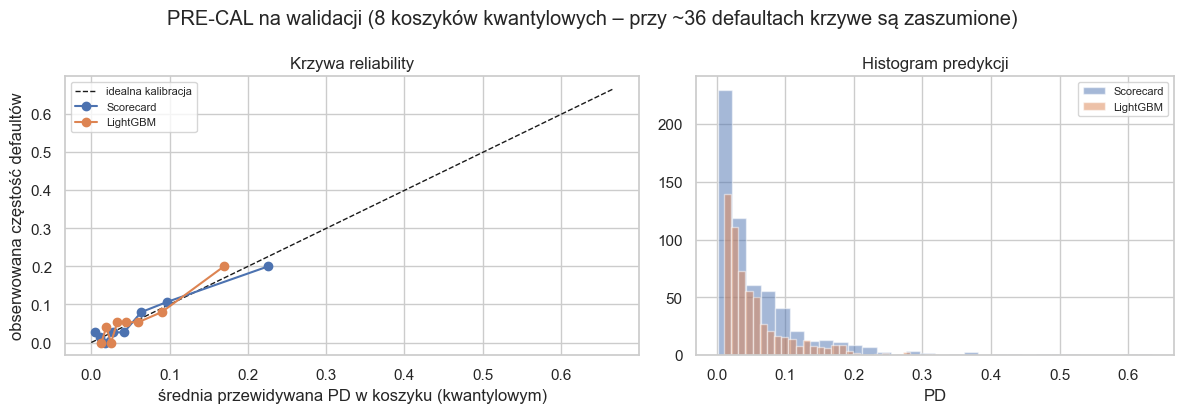

In [30]:
MODELS = ["Scorecard", "LightGBM"]
PIPES = {"Scorecard": pipe_lr, "LightGBM": pipe_bb}
P_VAL = {"Scorecard": p_val_lr, "LightGBM": p_val_bb}

def plot_reliability(curves, title, fname=None, n_bins=8):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
    mx = max(max(p.max(), reliability_table(y, p, n_bins)["obs_rate"].max()) for y, p in curves.values()) * 1.05
    a1.plot([0, mx], [0, mx], "k--", lw=1, label="idealna kalibracja")
    for lab, (y, p) in curves.items():
        t = reliability_table(y, p, n_bins); a1.plot(t.mean_pd, t.obs_rate, "o-", label=lab)
        a2.hist(p, bins=30, alpha=.5, label=lab)
    a1.set_xlabel("średnia przewidywana PD w koszyku (kwantylowym)"); a1.set_ylabel("obserwowana częstość defaultów"); a1.legend(fontsize=8); a1.set_title("Krzywa reliability")
    a2.set_xlabel("PD"); a2.set_title("Histogram predykcji"); a2.legend(fontsize=8); plt.suptitle(title); plt.tight_layout()
    if fname: plt.savefig(fname, dpi=150)
    plt.show()

pre = pd.DataFrame({m: all_metrics(yva, P_VAL[m]) for m in MODELS}).T
display(pre[["AUC", "Brier", "LogLoss", "CITL", "Slope", "ECE", "mean_PD", "obs_rate"]])
print("CITL > 0 => model zaniża ryzyko, < 0 => zawyża; Slope < 1 => predykcje zbyt rozproszone (nadmierna pewność), > 1 => zbyt skupione.")
plot_reliability({m: (yva, P_VAL[m]) for m in MODELS}, "PRE-CAL na walidacji (8 koszyków kwantylowych – przy ~36 defaultach krzywe są zaszumione)", "figures/reliability_precal.png")

### 5.2 Kalibracja statystyczna: Platt vs izotoniczna vs beta (CV wewnątrz validation) i wybór metody

In [31]:
class InterceptCalibrator:
    """
    Jednoparametrowa kalibracja interceptu.

    Dopasowuje średnią przewidywaną PD do częstości defaultów
    w zbiorze kalibracyjnym.

    Nie zmienia rankingu ryzyka ani nachylenia predykcji.
    """

    name = "Intercept"

    def fit(self, p, y):
        self.delta_ = shift_to_mean(
            p,
            target=float(np.mean(y))
        )
        return self

    def predict(self, p):
        return apply_shift(p, self.delta_)


CALS = {
    "brak": IdentityCalibrator,
    "Intercept": InterceptCalibrator,
    "Platt": PlattCalibrator,
    "Isotonic": IsotonicCalibrator,
    "Beta": BetaCalibrator
}
def cv_in_val(p, y, cal_cls, n_rep=20, n_splits=5):
    res, first = [], None
    for r in range(n_rep):
        oof = np.zeros(len(y))
        for a, b in StratifiedKFold(n_splits, shuffle=True, random_state=r).split(p, y):
            oof[b] = cal_cls().fit(p[a], y[a]).predict(p[b])
        res.append(all_metrics(y, oof)); first = oof if r == 0 else first
    r = pd.DataFrame(res); return r.mean(), r.std(), first

cal_rows, oof_first = [], {}
for m in MODELS:
    for name, cls in CALS.items():
        mu, sd, oof = cv_in_val(P_VAL[m], yva, cls); oof_first[(m, name)] = oof
        cal_rows.append(dict(model=m, metoda=name, Brier=mu.Brier, LogLoss=mu.LogLoss, LogLoss_std=sd.LogLoss, CITL=mu.CITL, Slope=mu.Slope, ECE=mu.ECE, AUC=mu.AUC))
cal_cmp = pd.DataFrame(cal_rows).set_index(["model", "metoda"]); display(cal_cmp)


# ============================================================
# WYBÓR KALIBRATORA
# ============================================================

# Log-loss jest główną metryką wyboru.
# Jeżeli kilka metod daje bardzo podobny wynik,
# preferujemy prostszą metodę.

CAL_COMPLEXITY = [
    "brak",
    "Intercept",
    "Platt",
    "Beta",
    "Isotonic"
]

REL_TOL = 0.005  # tolerancja 0,5% względem najlepszego LogLoss

BEST_CAL = {}

for m in MODELS:

    t = cal_cmp.loc[m]

    # Najniższy log-loss spośród wszystkich metod
    best_logloss = t["LogLoss"].min()

    # Metody mieszczące się w tolerancji 0,5%
    eligible = t.index[
        t["LogLoss"] <= best_logloss * (1 + REL_TOL)
    ].tolist()

    # Preferencja prostoty
    selected = next(
        method for method in CAL_COMPLEXITY
        if method in eligible
    )

    BEST_CAL[m] = selected


# ============================================================
# PORÓWNANIE Z WARIANTEM BEZ KALIBRACJI
# ============================================================

cal_cmp_view = cal_cmp.copy()

for m in MODELS:

    base_ll = cal_cmp.loc[(m, "brak"), "LogLoss"]
    base_bs = cal_cmp.loc[(m, "brak"), "Brier"]

    for method in CALS:

        cal_cmp_view.loc[(m, method), "ΔLogLoss"] = (
            cal_cmp.loc[(m, method), "LogLoss"] - base_ll
        )

        cal_cmp_view.loc[(m, method), "ΔBrier"] = (
            cal_cmp.loc[(m, method), "Brier"] - base_bs
        )


display(
    cal_cmp_view[
        ["Brier", "LogLoss", "ΔBrier", "ΔLogLoss",
         "CITL", "Slope", "ECE", "AUC"]
    ].round(5)
)

print("\nWYBRANE METODY:")
for m in MODELS:
    print(f"{m}: {BEST_CAL[m]}")

print(
    "\nKryterium: minimalizacja LogLoss, "
    "a w granicy 0,5% preferencja prostszej metody."
)


Brier  LogLoss  LogLoss_std    CITL  Slope    ECE    AUC
model     metoda                                                             
Scorecard brak      0.0499   0.1926       0.0000 -0.0212 0.9443 0.0137 0.7788
          Intercept 0.0499   0.1928       0.0002 -0.0031 0.9373 0.0137 0.7780
          Platt     0.0504   0.1953       0.0027  0.0002 0.9489 0.0147 0.7740
          Isotonic  0.0515   0.2111       0.0041 -0.0024 0.5826 0.0218 0.7461
          Beta      0.0509   0.1973       0.0027 -0.0027 0.8929 0.0175 0.7706
LightGBM  brak      0.0517   0.1994       0.0000  0.0613 1.1787 0.0169 0.7513
          Intercept 0.0517   0.1994       0.0001 -0.0017 1.1699 0.0140 0.7505
          Platt     0.0516   0.2008       0.0017  0.0002 0.9545 0.0128 0.7442
          Isotonic  0.0518   0.2166       0.0053 -0.0142 0.5385 0.0208 0.7031
          Beta      0.0511   0.2002       0.0018 -0.0019 0.9265 0.0153 0.7386

Brier  LogLoss  ΔBrier  ΔLogLoss    CITL  Slope    ECE    AUC
model     metoda                                                                  
Scorecard brak      0.0499   0.1926  0.0000    0.0000 -0.0212 0.9443 0.0137 0.7788
          Intercept 0.0499   0.1928  0.0000    0.0003 -0.0031 0.9373 0.0137 0.7780
          Platt     0.0504   0.1953  0.0006    0.0027  0.0002 0.9489 0.0147 0.7740
          Isotonic  0.0515   0.2111  0.0016    0.0185 -0.0024 0.5826 0.0218 0.7461
          Beta      0.0509   0.1973  0.0010    0.0047 -0.0027 0.8929 0.0175 0.7706
LightGBM  brak      0.0517   0.1994  0.0000    0.0000  0.0613 1.1787 0.0169 0.7513
          Intercept 0.0517   0.1994 -0.0001    0.0001 -0.0017 1.1699 0.0140 0.7505
          Platt     0.0516   0.2009 -0.0001    0.0014  0.0001 0.9545 0.0128 0.7442
          Isotonic  0.0518   0.2166  0.0001    0.0173 -0.0142 0.5385 0.0208 0.7031
          Beta      0.0511   0.2002 -0.0006    0.0008 -0.0019 0.9265 0.0153 0.7386


WYBRANE METODY:
Scorecard: brak
LightGBM: brak

Kryterium: minimalizacja LogLoss, a w granicy 0,5% preferencja prostszej metody.


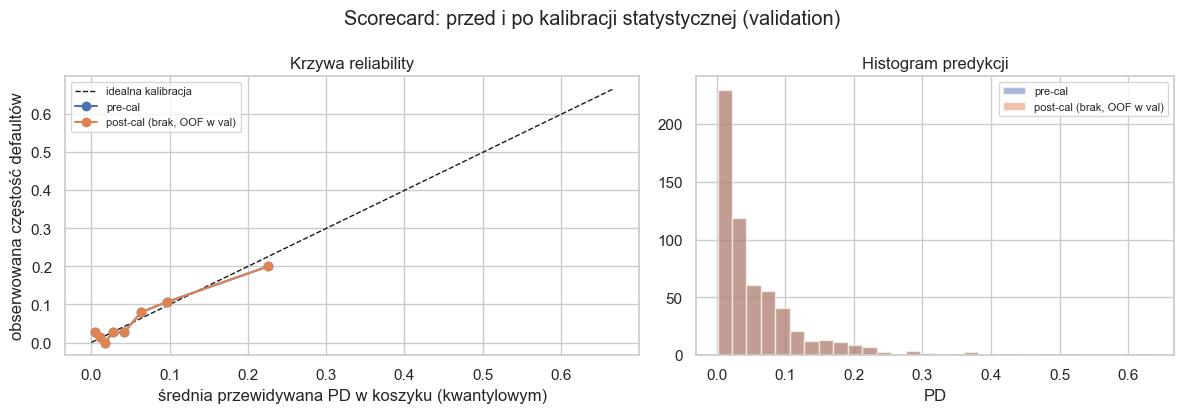

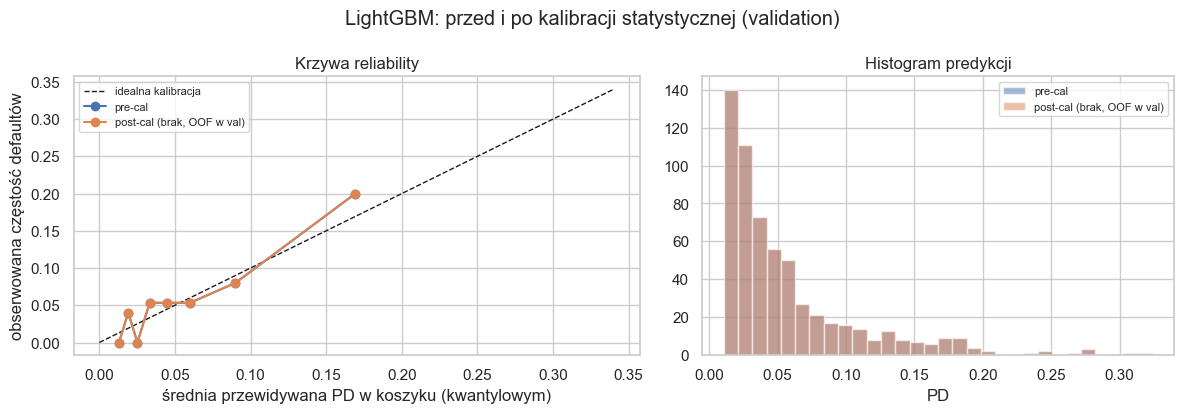

In [32]:
# post-cal (uczciwie: predykcje out-of-fold wewnątrz validation, 1. powtórzenie) – krzywe i metryki
for m in MODELS:
    plot_reliability({"pre-cal": (yva, P_VAL[m]), f"post-cal ({BEST_CAL[m]}, OOF w val)": (yva, oof_first[(m, BEST_CAL[m])])}, f"{m}: przed i po kalibracji statystycznej (validation)", f"figures/reliability_postcal_{m}.png")

### 5.3 Dostosowanie do PD = 4% (tendencja centralna) i **pierwsze użycie zbioru testowego**

**Rozróżnienie.** Kalibracja statystyczna (5.2) dopasowuje PD do częstości defaultów **w danych**. Dostosowanie do 4% to **zewnętrzne założenie biznesowe** o docelowym portfelu: przesuwamy intercept w skali logitowej o stałą δ tak, by średnia PD w populacji referencyjnej (= validation, bez testu) wynosiła 4%. Przesunięcie jest monotoniczne, więc **nie zmienia rankingu** (AUC bez zmian), a jeśli częstość defaultów w danych ≠ 4%, **pogarsza** statystyczną kalibrację względem próby – to konsekwencja założenia, nie błąd. Brak oversamplingu w modelach oznacza, że bazowe PD odpowiadają prevalencji próby.

In [33]:
TARGET_PD = 0.04
cal_final = {m: CALS[BEST_CAL[m]]().fit(P_VAL[m], yva) for m in MODELS}
p_val_cal = {m: cal_final[m].predict(P_VAL[m]) for m in MODELS}
delta = {m: shift_to_mean(p_val_cal[m], TARGET_PD) for m in MODELS}           # CITL-korekta wyznaczona na populacji referencyjnej (validation)
p_val_4 = {m: apply_shift(p_val_cal[m], delta[m]) for m in MODELS}

ref = pd.DataFrame({
    "default rate train": ytr.mean(), "default rate validation (referencja)": yva.mean(), "założone PD": TARGET_PD,
    "śr. PD pre-cal (val)": [P_VAL[m].mean() for m in MODELS], "śr. PD po kalibracji stat. (val)": [p_val_cal[m].mean() for m in MODELS],
    "δ (logit)": [delta[m] for m in MODELS], "mnożnik szans exp(δ)": [np.exp(delta[m]) for m in MODELS],
    "śr. PD po korekcie 4% (val)": [p_val_4[m].mean() for m in MODELS]}, index=MODELS)
display(ref.T)
print(f"Częstość defaultów w danych ({yva.mean():.1%}) jest {'wyższa' if yva.mean() > TARGET_PD else 'niższa'} niż 4% – korekta {'obniża' if delta[MODELS[0]] < 0 else 'podnosi'} PD względem próby.")

,Scorecard,LightGBM
default rate train,0.0589,0.0589
default rate validation (referencja),0.0600,0.0600
założone PD,0.0400,0.0400
śr. PD pre-cal (val),0.0611,0.0568
śr. PD po kalibracji stat. (val),0.0611,0.0568
δ (logit),-0.4936,-0.3848
mnożnik szans exp(δ),0.6104,0.6806
śr. PD po korekcie 4% (val),0.0400,0.0400


Częstość defaultów w danych (6.0%) jest wyższa niż 4% – korekta obniża PD względem próby.


#### Ocena na niezależnym zbiorze testowym (wszystkie decyzje zamrożone)

TEST: n=600, defaulty=36 (6.00%)


AUC  PR_AUC     KS  LogLoss  Brier    CITL  Slope    ECE  mean_PD  obs_rate
model     etap                                                                                                
Scorecard surowy                0.7813  0.2428 0.4858   0.1946 0.0509 -0.0140 0.9268 0.0095   0.0607    0.0600
          po kalibracji stat.   0.7813  0.2428 0.4858   0.1946 0.0509 -0.0140 0.9268 0.0095   0.0607    0.0600
          po dostosowaniu do 4% 0.7813  0.2428 0.4858   0.1998 0.0518  0.4796 0.9271 0.0220   0.0395    0.0600
LightGBM  surowy                0.8044  0.2472 0.5195   0.1928 0.0517 -0.0136 1.3200 0.0133   0.0607    0.0600
          po kalibracji stat.   0.8044  0.2472 0.5195   0.1928 0.0517 -0.0136 1.3200 0.0133   0.0607    0.0600
          po dostosowaniu do 4% 0.8044  0.2472 0.5195   0.1961 0.0527  0.3712 1.3201 0.0246   0.0429    0.0600

Metryki przy reważeniu testu do prevalencji 4% (obs_rate = 4% z konstrukcji):


LogLoss  Brier    CITL  Slope  mean_PD  obs_rate
model     etap                                                                   
Scorecard po kalibracji stat.     0.1495 0.0364 -0.4405 0.9322   0.0587    0.0400
          po dostosowaniu do 4%   0.1456 0.0356  0.0530 0.9324   0.0382    0.0400
LightGBM  po kalibracji stat.     0.1485 0.0365 -0.4345 1.3252   0.0594    0.0400
          po dostosowaniu do 4%   0.1446 0.0361 -0.0497 1.3192   0.0419    0.0400

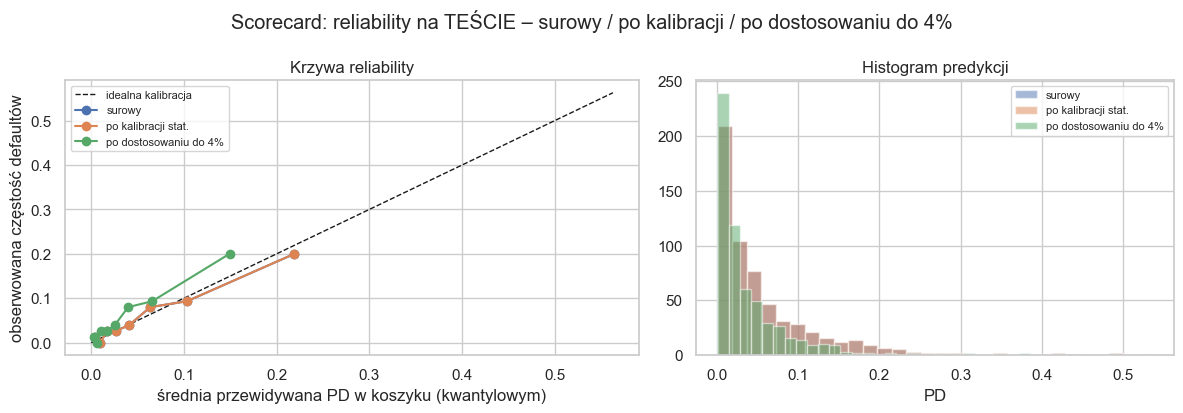

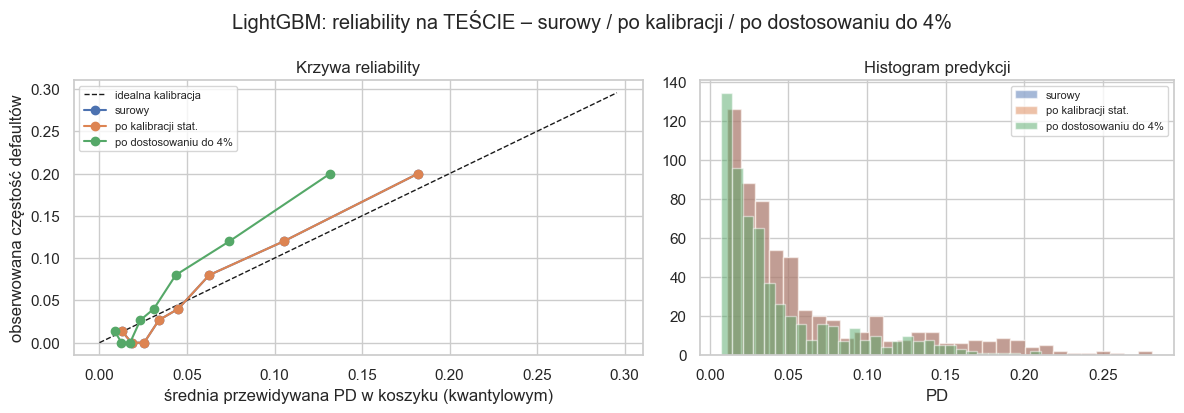

,mean,min,10%,50%,90%,99%,max
Scorecard | surowy,0.0607,0.0010,0.0060,0.0334,0.1520,0.4165,0.5359
Scorecard | po kalibracji stat.,0.0607,0.0010,0.0060,0.0334,0.1520,0.4165,0.5359
Scorecard | po dostosowaniu do 4%,0.0395,0.0006,0.0036,0.0207,0.0986,0.3035,0.4134
LightGBM | surowy,0.0607,0.0106,0.0141,0.0394,0.1494,0.2308,0.2815
LightGBM | po kalibracji stat.,0.0607,0.0106,0.0141,0.0394,0.1494,0.2308,0.2815
LightGBM | po dostosowaniu do 4%,0.0429,0.0072,0.0096,0.0272,0.1068,0.1696,0.2105


In [34]:
Xte, yte = df.iloc[idx_test], y_all[idx_test]
p_te_raw = {m: PIPES[m].predict_proba(Xte)[:, 1] for m in MODELS}
p_te_cal = {m: cal_final[m].predict(p_te_raw[m]) for m in MODELS}
p_te_4 = {m: apply_shift(p_te_cal[m], delta[m]) for m in MODELS}
print(f"TEST: n={len(yte)}, defaulty={yte.sum()} ({yte.mean():.2%})")

stages = lambda m: [("surowy", p_te_raw[m]), ("po kalibracji stat.", p_te_cal[m]), ("po dostosowaniu do 4%", p_te_4[m])]
test_tab = pd.DataFrame([{"model": m, "etap": s, **all_metrics(yte, p)} for m in MODELS for s, p in stages(m)]).set_index(["model", "etap"])
display(test_tab[["AUC", "PR_AUC", "KS", "LogLoss", "Brier", "CITL", "Slope", "ECE", "mean_PD", "obs_rate"]])

# ocena przy założeniu przesunięcia prevalencji do 4% (waga: defaulty 0.04/π_test, dobrzy 0.96/(1−π_test)); zakłada stałe rozkłady cech w klasach
w_te = np.where(yte == 1, TARGET_PD / yte.mean(), (1 - TARGET_PD) / (1 - yte.mean()))
wtab = pd.DataFrame([{"model": m, "etap": s, **{k: v for k, v in all_metrics(yte, p, w_te).items() if k in ("Brier", "LogLoss", "CITL", "Slope", "mean_PD", "obs_rate")}}
                     for m in MODELS for s, p in stages(m)[1:]]).set_index(["model", "etap"])
print("Metryki przy reważeniu testu do prevalencji 4% (obs_rate = 4% z konstrukcji):"); display(wtab)

for m in MODELS:
    plot_reliability({s: (yte, p) for s, p in stages(m)}, f"{m}: reliability na TEŚCIE – surowy / po kalibracji / po dostosowaniu do 4%", f"figures/reliability_test_{m}.png")
dist = pd.DataFrame({f"{m} | {s}": pd.Series(p).describe(percentiles=[.1, .5, .9, .99]) for m in MODELS for s, p in stages(m)}).T[["mean", "min", "10%", "50%", "90%", "99%", "max"]]
display(dist)

**Do opisania w raporcie (3.5):**
* Pre-cal: kierunek i skala błędu kalibracji (CITL, slope) obu modeli; czy black-box jest bardziej „pewny siebie" (slope < 1) niż scorecard.
* Wybór metody: tabela CV-w-val (czy izotoniczna przeucza się przy ~36 defaultach; ewentualne remisy w rankingu po izotonicznej).
* Po korekcie 4%: średnia PD na teście ≈ 4% *nie musi* być dokładna; CITL względem **próby testowej** jest dodatny (PD niższe niż częstość defaultów w próbie, czyli model „zaniża” ryzyko względem próby) – to skutek założenia 4% < częstość w danych, a nie błąd modelu. Ocena po reważeniu do 4% pokazuje, czy po przyjęciu założenia o przesunięciu prevalencji PD są spójne.
* AUC/KS identyczne przed/po korekcie (monotoniczna transformacja) – ranking ryzyka niezmieniony.

## 6. Progi decyzji, ratingi i analiza kontrfaktyczna (3.6)

### 6.1 Funkcja kosztu/korzyści i próg operacyjny
Założenia **do zmiany przez zespół** (ilustracyjne): zysk z obsłużenia dobrego klienta = `MARGIN` (% ekspozycji), strata na defaulcie = `LGD` (% ekspozycji). Odrzucamy klienta, gdy PD ≥ próg. Pozytyw = odrzucenie: TP – odrzucony default; FP – odrzucony dobry (utracona marża); FN – przyjęty default (strata LGD); TN – przyjęty dobry. Zysk = MARGIN·TN − LGD·FN. Teoretyczny próg opłacalności (przy poprawnie skalibrowanej PD): `MARGIN/(MARGIN+LGD)`.

Próg wybieramy na **validation** (zysk empiryczny na PD po kalibracji statystycznej, czyli w skali częstości z próby), a jego odpowiednik w skali PD po korekcie 4% wyznaczamy odwrotnym przesunięciem.

,próg* (skala próby),próg* (skala PD 4%),% odrzuceń na val przy progu*,zysk/klienta na val przy progu*,zysk/klienta: przyjmij wszystkich,próg teoretyczny (skala 4%),próg teoretyczny przeliczony na skalę próby
Scorecard,0.1585,0.1031,8.8333,0.0369,0.0294,0.1176,0.1793
LightGBM,0.1809,0.1307,3.5000,0.0367,0.0294,0.1176,0.1638


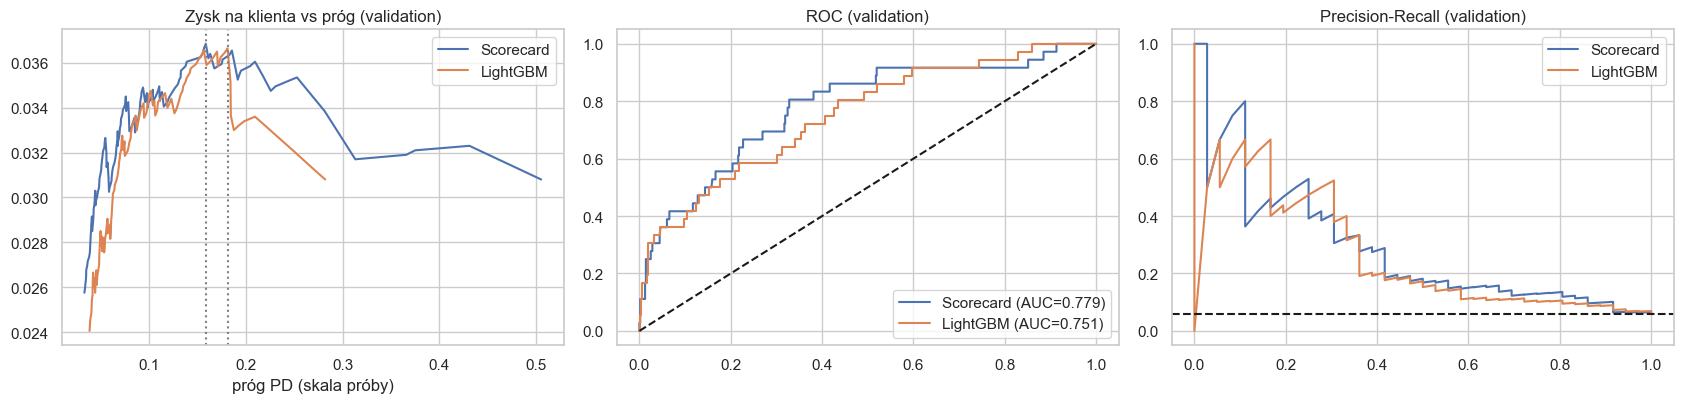

In [35]:
MARGIN, LGD = 0.06, 0.45
t_theory = MARGIN / (MARGIN + LGD)
t_star, curves = {}, {}
for m in MODELS:
    grid_t = np.unique(np.quantile(p_val_cal[m], np.linspace(0.5, 0.995, 150)))
    cu = pd.DataFrame([decision_table(yva, p_val_cal[m], t, MARGIN, LGD) for t in grid_t]); curves[m] = cu
    t_star[m] = float(cu.loc[cu.zysk_na_klienta.idxmax(), "prog"])
base_profit = MARGIN * (1 - yva.mean()) - LGD * yva.mean()
thr_tab = pd.DataFrame({"próg* (skala próby)": t_star, "próg* (skala PD 4%)": {m: float(apply_shift(t_star[m], delta[m])) for m in MODELS},
                        "% odrzuceń na val przy progu*": {m: 100 * (p_val_cal[m] >= t_star[m]).mean() for m in MODELS},
                        "zysk/klienta na val przy progu*": {m: curves[m].zysk_na_klienta.max() for m in MODELS}})
thr_tab["zysk/klienta: przyjmij wszystkich"] = base_profit
thr_tab["próg teoretyczny (skala 4%)"] = t_theory
thr_tab["próg teoretyczny przeliczony na skalę próby"] = {m: float(apply_shift(t_theory, -delta[m])) for m in MODELS}
display(thr_tab)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for m in MODELS:
    ax[0].plot(curves[m].prog, curves[m].zysk_na_klienta, label=m); ax[0].axvline(t_star[m], ls=":", color="grey")
    fpr, tpr, _ = roc_curve(yva, p_val_cal[m]); ax[1].plot(fpr, tpr, label=f"{m} (AUC={roc_auc_score(yva, p_val_cal[m]):.3f})")
    pr, rc, _ = precision_recall_curve(yva, p_val_cal[m]); ax[2].plot(rc, pr, label=m)
ax[0].set_title("Zysk na klienta vs próg (validation)"); ax[0].set_xlabel("próg PD (skala próby)"); ax[0].legend()
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC (validation)"); ax[1].legend(); ax[2].set_title("Precision-Recall (validation)"); ax[2].axhline(yva.mean(), color="k", ls="--"); ax[2].legend()
plt.tight_layout(); plt.savefig("figures/thresholds.png", dpi=150); plt.show()

In [36]:
# tabele decyzyjne na TEŚCIE: (a) próg* wybrany na validation, (b) wrażliwość na próg przez poziom odrzuceń ustalony na validation
rows = []
for m in MODELS:
    rows.append({"model": m, "wariant": "próg* (val)", **decision_table(yte, p_te_cal[m], t_star[m], MARGIN, LGD)})
    for r in (5, 10, 15, 20, 30):
        rows.append({"model": m, "wariant": f"odrzuć ~{r}% (próg z val)", **decision_table(yte, p_te_cal[m], float(np.quantile(p_val_cal[m], 1 - r / 100)), MARGIN, LGD)})
    rows.append({"model": m, "wariant": "przyjmij wszystkich", **decision_table(yte, p_te_cal[m], 1.01, MARGIN, LGD)})
dec_tab = pd.DataFrame(rows).set_index(["model", "wariant"]); display(dec_tab)

# porównanie decyzji obu modeli przy własnych progach*
rej = {m: p_te_cal[m] >= t_star[m] for m in MODELS}
print(f"Zgodność decyzji: {np.mean(rej['Scorecard'] == rej['LightGBM']):.1%} | kappa Cohena: {cohen_kappa_score(rej['Scorecard'], rej['LightGBM']):.2f}")
display(pd.crosstab(pd.Series(rej["Scorecard"], name="Scorecard odrzuca"), pd.Series(rej["LightGBM"], name="LightGBM odrzuca")))

prog  odrzucenia_proc  TP   FP  FN   TN  bad_rate_przyjetych  recall_defaultow  zysk_na_klienta
model     wariant                                                                                                                   
Scorecard próg* (val)              0.1585           9.5000  13   44  23  520               0.0424            0.3611           0.0348
          odrzuć ~5% (próg z val)  0.1998           5.3333  11   21  25  543               0.0440            0.3056           0.0355
          odrzuć ~10% (próg z val) 0.1419          11.3333  14   54  22  510               0.0414            0.3889           0.0345
          odrzuć ~15% (próg z val) 0.1102          17.1667  18   85  18  479               0.0362            0.5000           0.0344
          odrzuć ~20% (próg z val) 0.0910          22.0000  21  111  15  453               0.0321            0.5833           0.0340
          odrzuć ~30% (próg z val) 0.0673          30.0000  27  153   9  411               0.0214            0.7500           0.0343
          przyjmij wszystkich      1.0100           0.0000   0    0  36  564               0.0600            0.0000           0.0294
LightGBM  próg* (val)              0.1809           5.8333   9   26  27  538               0.0478            0.2500           0.0336
          odrzuć ~5% (próg z val)  0.1707           7.6667  10   36  26  528               0.0469            0.2778           0.0333
          odrzuć ~10% (próg z val) 0.1317          12.8333  16   61  20  503               0.0382            0.4444           0.0353
          odrzuć ~15% (próg z val) 0.1025          19.8333  21   98  15  466               0.0312            0.5833           0.0353
          odrzuć ~20% (próg z val) 0.0856          23.1667  24  115  12  449               0.0260            0.6667           0.0359
          odrzuć ~30% (próg z val) 0.0611          31.3333  27  161   9  403               0.0218            0.7500           0.0335
          przyjmij wszystkich      1.0100           0.0000   0    0  36  564               0.0600            0.0000           0.0294

Zgodność decyzji: 94.0% | kappa Cohena: 0.58


LightGBM odrzuca,False,True
Scorecard odrzuca,,
False,536,7
True,29,28


### 6.2 Mapowanie PD → klasy ratingowe
Skala nadrzędna na PD po korekcie 4% (progi: 0,5%, 1%, 2%, 4%, 8%, 15% → AAA, AA, A, BBB, BB, B, CCC); po scaleniu klasa dostaje etykietę klasy skali nadrzędnej, w której leży jej średnia PD (dzięki temu etykiety są porównywalne między modelami). Granice są dopasowywane na **validation**: sąsiednie klasy są łączone, jeśli obserwowana częstość defaultów nie rośnie z klasą albo klasa ma < 15 obserwacji – dzięki temu zachowana jest **monotoniczność** (średnia PD rośnie z klasą z konstrukcji, obserwowana częstość – po scaleniu na zbiorze referencyjnym). Monotoniczność obserwowanej częstości na **teście** nie jest gwarantowana (małe liczebności) – ewentualne naruszenie to wynik do opisania, nie błąd. Klasa **D** oznacza *stwierdzony* default (nie wynika z PD) i funkcja `assign_rating(..., known_default=...)` ją przypisuje; w tabelach poniżej oceniamy populację niezdefaultowaną w momencie oceny.

Scorecard: granice PD(4%) = [0.02, 0.04, 0.08, 0.15] -> klasy ['AA', 'BBB', 'BB', 'B', 'CCC']
LightGBM: granice PD(4%) = [0.01, 0.02, 0.08] -> klasy ['AA', 'A', 'BBB', 'B']

=== Scorecard: VALIDATION (monotoniczność średniej PD, obs. częstości): (True, True)


,n,defaulty,srednia_PD,obs_default_rate,udzial_%,CI95_lo,CI95_hi
klasa,,,,,,,
AA,297,5,0.0092,0.0168,49.5000,0.0072,0.0388
BBB,112,6,0.0287,0.0536,18.6667,0.0248,0.1120
BB,117,10,0.0554,0.0855,19.5000,0.0471,0.1502
B,50,5,0.1093,0.1000,8.3333,0.0435,0.2136
CCC,24,10,0.2546,0.4167,4.0000,0.2447,0.6117


=== Scorecard: TEST (monotoniczność średniej PD, obs. częstości): (True, True)


,n,defaulty,srednia_PD,obs_default_rate,udzial_%,CI95_lo,CI95_hi
klasa,,,,,,,
AA,296,5,0.0088,0.0169,49.3333,0.0072,0.0389
BBB,119,4,0.0287,0.0336,19.8333,0.0131,0.0832
BB,100,11,0.0569,0.1100,16.6667,0.0625,0.1863
B,66,9,0.1099,0.1364,11.0000,0.0734,0.2393
CCC,19,7,0.2505,0.3684,3.1667,0.1915,0.5896


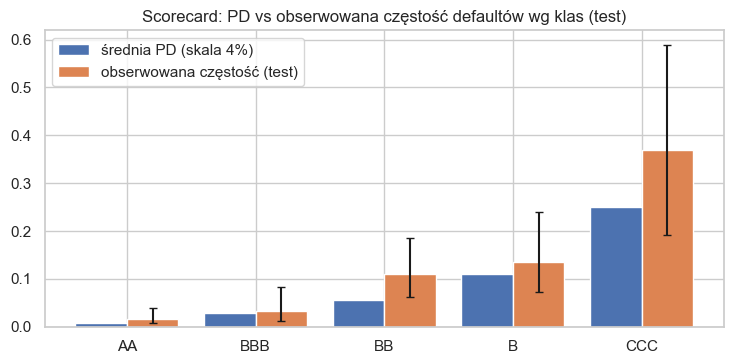


=== LightGBM: VALIDATION (monotoniczność średniej PD, obs. częstości): (True, True)


,n,defaulty,srednia_PD,obs_default_rate,udzial_%,CI95_lo,CI95_hi
klasa,,,,,,,
AA,63,0,0.0086,0.0000,10.5000,-0.0000,0.0575
A,158,3,0.0147,0.0190,26.3333,0.0065,0.0543
BBB,302,18,0.0391,0.0596,50.3333,0.0380,0.0922
B,77,15,0.1213,0.1948,12.8333,0.1218,0.2969


=== LightGBM: TEST (monotoniczność średniej PD, obs. częstości): (True, False)


,n,defaulty,srednia_PD,obs_default_rate,udzial_%,CI95_lo,CI95_hi
klasa,,,,,,,
AA,68,1,0.0087,0.0147,11.3333,0.0026,0.0787
A,151,0,0.0146,0.0000,25.1667,0.0000,0.0248
BBB,284,15,0.0390,0.0528,47.3333,0.0323,0.0853
B,97,20,0.1222,0.2062,16.1667,0.1376,0.2971


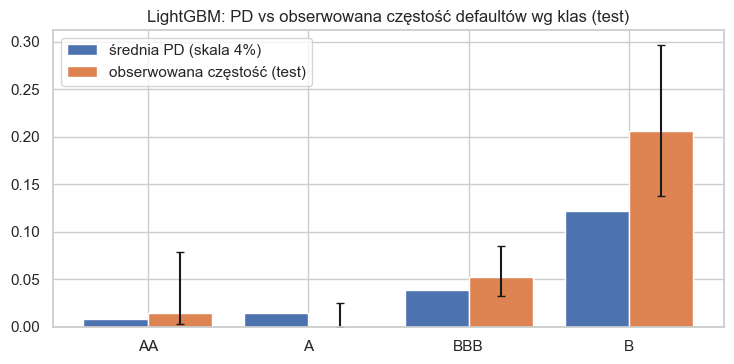

In [37]:
from scorecard import RATING_LABELS
BOUNDS0 = [0.005, 0.01, 0.02, 0.04, 0.08, 0.15]
rating_def = {}
for m in MODELS:
    b = monotone_bounds(p_val_4[m], yva, BOUNDS0, min_n=15); rating_def[m] = (b, labels_from_master(p_val_4[m], b, BOUNDS0))
    print(f"{m}: granice PD(4%) = {[round(x, 4) for x in b]} -> klasy {rating_def[m][1]}")

for m in MODELS:
    tv, tt = rating_table(p_val_4[m], yva, *rating_def[m]), rating_table(p_te_4[m], yte, *rating_def[m])
    mono = lambda t: (bool(np.all(np.diff(t["srednia_PD"].dropna().values) > 0)), bool(np.all(np.diff(t["obs_default_rate"].dropna().values) > 0)))
    print(f"\n=== {m}: VALIDATION (monotoniczność średniej PD, obs. częstości): {mono(tv)}"); display(tv)
    print(f"=== {m}: TEST (monotoniczność średniej PD, obs. częstości): {mono(tt)}"); display(tt)
    fig, ax = plt.subplots(figsize=(7.5, 3.8)); x = np.arange(len(tt))
    ax.bar(x - .2, tt["srednia_PD"], .4, label="średnia PD (skala 4%)"); ax.bar(x + .2, tt["obs_default_rate"], .4, label="obserwowana częstość (test)",
        yerr=[tt["obs_default_rate"] - tt["CI95_lo"], tt["CI95_hi"] - tt["obs_default_rate"]], capsize=3)
    ax.set_xticks(x); ax.set_xticklabels(tt.index); ax.set_title(f"{m}: PD vs obserwowana częstość defaultów wg klas (test)"); ax.legend(); plt.tight_layout(); plt.savefig(f"figures/ratings_{m}.png", dpi=150); plt.show()

In [38]:
# macierz migracji ratingów między modelami (test)
cl = {m: assign_rating(p_te_4[m], *rating_def[m]) for m in MODELS}
cat = lambda a: pd.Categorical(a, categories=RATING_LABELS, ordered=True)
display(pd.crosstab(cat(cl["Scorecard"]), cat(cl["LightGBM"]), rownames=["Scorecard"], colnames=["LightGBM"], dropna=False))
pos = {l: i for i, l in enumerate(RATING_LABELS)}; dd = np.abs(np.array([pos[a] for a in cl["Scorecard"]]) - np.array([pos[b] for b in cl["LightGBM"]]))
print(f"Ta sama klasa: {np.mean(dd == 0):.1%} | różnica ≤1 klasy: {np.mean(dd <= 1):.1%} (uwaga: modele mogą mieć różną liczbę klas po scaleniu)")

LightGBM,AAA,AA,A,BBB,BB,B,CCC
Scorecard,,,,,,,
AAA,0,0,0,0,0,0,0
AA,0,68,137,91,0,0,0
A,0,0,0,0,0,0,0
BBB,0,0,13,103,0,3,0
BB,0,0,1,72,0,27,0
B,0,0,0,16,0,50,0
CCC,0,0,0,2,0,17,0


Ta sama klasa: 36.8% | różnica ≤1 klasy: 81.2% (uwaga: modele mogą mieć różną liczbę klas po scaleniu)


### 6.3 Audyt podgrup (test)
Szybki audyt różnic jakości i PD w podgrupach: wielkość firmy (kwartyle `Aktywa` z train) oraz forma własności. **Liczebności defaultów w podgrupach są bardzo małe** (kilka–kilkanaście), więc AUC jest raportowane tylko przy ≥5 defaultach i ≥5 dobrych, a wnioski mają charakter orientacyjny.

In [39]:
akt_edges = np.r_[-np.inf, Xtr["Aktywa"].quantile([.25, .5, .75]).values, np.inf]
g_akt = pd.cut(Xte["Aktywa"], akt_edges, labels=["Q1 małe", "Q2", "Q3", "Q4 duże"])
frequent = Xtr["forma_wl"].value_counts(); frequent = frequent[frequent >= 100].index
g_forma = Xte["forma_wl"].where(Xte["forma_wl"].isin(frequent), "inne")
aud = []
for gname, g in {"wielkość (Aktywa)": g_akt, "forma własności": g_forma}.items():
    for lvl in g.dropna().unique():
        mask = (g == lvl).values; n, d = int(mask.sum()), int(yte[mask].sum())
        for m in MODELS:
            ok = d >= 5 and n - d >= 5
            aud.append(dict(grupa=gname, poziom=str(lvl), model=m, n=n, defaulty=d, AUC=roc_auc_score(yte[mask], p_te_4[m][mask]) if ok else np.nan,
                            Brier_po_kal_stat=np.mean((p_te_cal[m][mask] - yte[mask]) ** 2), sr_PD_4proc=p_te_4[m][mask].mean(), obs_rate=yte[mask].mean()))
display(pd.DataFrame(aud).sort_values(["grupa", "poziom", "model"]).set_index(["grupa", "poziom", "model"]))

n  defaulty    AUC  Brier_po_kal_stat  sr_PD_4proc  obs_rate
grupa             poziom  model                                                                    
forma własności   214     LightGBM   402        21 0.7702             0.0463       0.0448    0.0522
                          Scorecard  402        21 0.7520             0.0453       0.0374    0.0522
                  215     LightGBM    62         5 0.9298             0.0624       0.0403    0.0806
                          Scorecard   62         5 0.8947             0.0614       0.0412    0.0806
                  216     LightGBM    33         2    NaN             0.0465       0.0336    0.0606
                          Scorecard   33         2    NaN             0.0412       0.0435    0.0606
                  inne    LightGBM   103         8 0.8118             0.0682       0.0399    0.0777
                          Scorecard  103         8 0.7750             0.0696       0.0456    0.0777
wielkość (Aktywa) Q1 małe LightGBM   163        15 0.6401             0.0826       0.0662    0.0920
                          Scorecard  163        15 0.6286             0.0839       0.0560    0.0920
                  Q2      LightGBM   157         9 0.8679             0.0468       0.0456    0.0573
                          Scorecard  157         9 0.8198             0.0468       0.0465    0.0573
                  Q3      LightGBM   137         7 0.9022             0.0418       0.0330    0.0511
                          Scorecard  137         7 0.8352             0.0419       0.0322    0.0511
                  Q4 duże LightGBM   143         5 0.7594             0.0314       0.0228    0.0350
                          Scorecard  143         5 0.7551             0.0265       0.0202    0.0350

### 6.4 Analiza kontrfaktyczna (obowiązkowa)

Cel: dla jednej obserwacji (walidacja, nie-default, scorecard-rating **BB**) znaleźć **najmniejszą realistyczną zmianę wskaźników**, która poprawi rating o jedną klasę (BB → BBB), tj. obniży PD (po korekcie 4%) poniżej granicy klas.

Założenia realistyczności:
* zmieniamy tylko wskaźniki użyte w scorecardzie (bez wielkości firmy i zmiennych spoza opisu), **w kierunku zmniejszającym ryzyko**, w zakresie p5–p95 rozkładu train (bez ekstrapolacji), do 1 lub 2 wskaźników jednocześnie,
* koszt zmiany = przesunięcie w **percentylach** rozkładu train (porównywalne między wskaźnikami), limit 50 pkt percentylowych na wskaźnik,
* **zależności między cechami:** gdy zmieniamy wskaźnik, skorelowane z nim wskaźniki (|ρ Spearmana| ≥ 0,7) przesuwają się razem wg regresji liniowej z train (z obcięciem do zakresu p1–p99); nie jest to model przyczynowy, tylko przybliżenie spójności księgowej,
* weryfikujemy wynik także w modelu black-box.

In [40]:
labels_lr, bounds_lr = rating_def["Scorecard"][1], rating_def["Scorecard"][0]
assert len(labels_lr) >= 2, "Za mało klas ratingowych po scaleniu – zmień BOUNDS0/min_n"
ci = labels_lr.index("BB") if "BB" in labels_lr and labels_lr.index("BB") >= 1 else min(len(labels_lr) - 2, max(1, len(labels_lr) // 2 + 1))
cls_val = assign_rating(p_val_4["Scorecard"], bounds_lr, labels_lr)
cand = np.where((cls_val == labels_lr[ci]) & (yva == 0))[0]
if len(cand) == 0: cand = np.where(cls_val == labels_lr[ci])[0]
i_cf = int(cand[np.argmin(np.abs(p_val_4["Scorecard"][cand] - np.median(p_val_4["Scorecard"][cand])))])
boundary = bounds_lr[ci - 1]; target_pd = boundary * 0.98
pd4 = lambda m, rows: apply_shift(cal_final[m].predict(PIPES[m].predict_proba(rows)[:, 1]), delta[m])
base = Xva.iloc[[i_cf]]
print(f"Obserwacja (val, pozycja {i_cf}): y={yva[i_cf]} | rating scorecard: {labels_lr[ci]} -> cel: {labels_lr[ci - 1]} | PD(4%) scorecard={pd4('Scorecard', base)[0]:.4f}, LightGBM={pd4('LightGBM', base)[0]:.4f} | cel PD < {target_pd:.4f}")

Obserwacja (val, pozycja 563): y=0 | rating scorecard: BB -> cel: BBB | PD(4%) scorecard=0.0547, LightGBM=0.0743 | cel PD < 0.0392


In [41]:
# dźwignie i zależności
iv_t = prep_lr.iv_table_
LEVERS = [f for f in (raw_name(c) for c in feats_lr) if f in RATIO_COLS and f not in SUSPICIOUS and not np.isnan(base[f].iloc[0])]
direction = {f: (-1 if iv_t.loc[f, "kierunek"] == "inc" else 1) for f in LEVERS}      # kierunek ZMNIEJSZAJĄCY ryzyko
fin = lambda f: Xtr[f].replace([np.inf, -np.inf], np.nan).dropna().values
srt = {f: np.sort(fin(f)) for f in RATIO_COLS}
pct = lambda f, v: 100 * np.searchsorted(srt[f], v) / len(srt[f])
rng_pct = lambda f, q: float(np.quantile(srt[f], q))
corr_sp = Xtr[RATIO_COLS].replace([np.inf, -np.inf], np.nan).corr(method="spearman")
def clipped(f): return np.clip(Xtr[f].replace([np.inf, -np.inf], np.nan), rng_pct(f, .01), rng_pct(f, .99))
dep = {}
for f in LEVERS:
    xf = clipped(f); lst = []
    for j in RATIO_COLS:
        if j != f and abs(corr_sp.loc[f, j]) >= 0.7 and np.isfinite(base[j].iloc[0]):
            xj = clipped(j); ok = xf.notna() & xj.notna(); lst.append((j, float(np.cov(xf[ok], xj[ok])[0, 1] / np.var(xf[ok], ddof=1))))
    dep[f] = lst
print("Dźwignie:", LEVERS); print({f: len(dep[f]) for f in LEVERS}, "<- liczba cech skorelowanych (aktualizowanych razem z dźwignią)")

def build_rows(changes):
    n = len(changes[0][1]); rows = base.loc[base.index.repeat(n)].reset_index(drop=True); upd = {}
    for f, vals in changes:
        v0 = float(base[f].iloc[0]); rows[f] = vals
        for j, b in dep[f]:
            if j not in [c[0] for c in changes]: upd[j] = upd.get(j, 0) + b * (vals - v0)
    for j, d in upd.items():
        xj = float(base[j].iloc[0]); rows[j] = np.clip(xj + d, min(rng_pct(j, .01), xj), max(rng_pct(j, .99), xj))
    return rows

MAX_MOVE = 50.0
def grid_for(f, n):
    v0 = float(base[f].iloc[0]); e = rng_pct(f, .95 if direction[f] > 0 else .05)
    return None if direction[f] * (e - v0) <= 0 else np.linspace(v0, e, n + 1)[1:]
def cost(f, vals): return np.abs(pct(f, vals) - pct(f, float(base[f].iloc[0])))

res = []
for f in LEVERS:                                   # pojedyncze dźwignie
    g = grid_for(f, 25)
    if g is None: continue
    rws = build_rows([(f, g)]); pl, pb = pd4("Scorecard", rws), pd4("LightGBM", rws); c = cost(f, g)
    res += [dict(dzwignie=(f,), nowe=(float(g[k]),), koszt=float(c[k]), PD_sc=float(pl[k]), PD_lgbm=float(pb[k])) for k in range(len(g))]
for f, h in combinations(LEVERS, 2):                # pary dźwigni
    gf, gh = grid_for(f, 10), grid_for(h, 10)
    if gf is None or gh is None: continue
    A, B = np.meshgrid(gf, gh); A, B = A.ravel(), B.ravel(); rws = build_rows([(f, A), (h, B)]); pl, pb = pd4("Scorecard", rws), pd4("LightGBM", rws); c = cost(f, A) + cost(h, B)
    res += [dict(dzwignie=(f, h), nowe=(float(A[k]), float(B[k])), koszt=float(c[k]), PD_sc=float(pl[k]), PD_lgbm=float(pb[k])) for k in range(len(A))]
res = pd.DataFrame(res)
res["ruch_max_na_wskaźnik_ok"] = [all(cost(f, np.array([v]))[0] <= MAX_MOVE for f, v in zip(d, nv)) for d, nv in zip(res.dzwignie, res.nowe)]
feas = res[(res.PD_sc <= target_pd) & res.ruch_max_na_wskaźnik_ok]
print(f"Przeszukano {len(res)} kombinacji; spełniających cel (scorecard) i limity realności: {len(feas)}")

Dźwignie: ['wsk_mnoznik_kap_wl', 'wsk_poziom_kapitalu_obrotowego_netto', 'wsk_ebitda_1', 'wsk_ROE', 'wsk_rent_kaptial_podstawowy', 'wsk_sprzedaz_kap_obrotowy', 'wsk_zysk_ebitda_3', 'wsk_zadluzenia_pozyczki_dlugie']
{'wsk_mnoznik_kap_wl': 14, 'wsk_poziom_kapitalu_obrotowego_netto': 0, 'wsk_ebitda_1': 30, 'wsk_ROE': 28, 'wsk_rent_kaptial_podstawowy': 27, 'wsk_sprzedaz_kap_obrotowy': 2, 'wsk_zysk_ebitda_3': 3, 'wsk_zadluzenia_pozyczki_dlugie': 3} <- liczba cech skorelowanych (aktualizowanych razem z dźwignią)
Przeszukano 1650 kombinacji; spełniających cel (scorecard) i limity realności: 7


In [42]:
def show_cf(row, title):
    f_list, new = row.dzwignie, row.nowe
    t = pd.DataFrame({"wskaźnik": f_list, "przed": [float(base[f].iloc[0]) for f in f_list], "po": new,
                      "percentyl_przed": [pct(f, float(base[f].iloc[0])) for f in f_list], "percentyl_po": [pct(f, v) for f, v in zip(f_list, new)]})
    print(f"--- {title}: koszt = {row.koszt:.1f} pkt percentylowych"); display(t)
    print(f"    PD(4%) scorecard: {pd4('Scorecard', base)[0]:.4f} -> {row.PD_sc:.4f} | rating {labels_lr[ci]} -> {assign_rating([row.PD_sc], bounds_lr, labels_lr)[0]}")
    bnd_b, lab_b = rating_def["LightGBM"]; print(f"    PD(4%) LightGBM : {pd4('LightGBM', base)[0]:.4f} -> {row.PD_lgbm:.4f} | rating LightGBM {assign_rating([pd4('LightGBM', base)[0]], bnd_b, lab_b)[0]} -> {assign_rating([row.PD_lgbm], bnd_b, lab_b)[0]}")

cf_rows = {}
if len(feas):
    for kind in (1, 2):
        s = feas[feas.dzwignie.map(len) == kind]
        if len(s): cf_rows[kind] = s.sort_values("koszt").iloc[0]; show_cf(cf_rows[kind], f"Najtańszy kontrfaktyk z {kind} wskaźnik{'iem' if kind == 1 else 'ami'}")
else:
    print("Brak kontrfaktyka w dozwolonych granicach – zwiększ MAX_MOVE lub dopuść więcej dźwigni (i opisz to w raporcie).")

--- Najtańszy kontrfaktyk z 1 wskaźnikiem: koszt = 40.9 pkt percentylowych


,wskaźnik,przed,po,percentyl_przed,percentyl_po
0,wsk_ROE,0.0000,0.0519,20.3889,61.3333


    PD(4%) scorecard: 0.0547 -> 0.0387 | rating BB -> BBB
    PD(4%) LightGBM : 0.0743 -> 0.0684 | rating LightGBM BBB -> BBB
--- Najtańszy kontrfaktyk z 2 wskaźnikami: koszt = 76.5 pkt percentylowych


,wskaźnik,przed,po,percentyl_przed,percentyl_po
0,wsk_ROE,0.0000,0.0649,20.3889,62.7778
1,wsk_zysk_ebitda_3,0.0000,0.1548,7.1667,41.2778


    PD(4%) scorecard: 0.0547 -> 0.0288 | rating BB -> BBB
    PD(4%) LightGBM : 0.0743 -> 0.0567 | rating LightGBM BBB -> BBB


In [43]:
# porównanie z wyjaśnieniami SHAP / LIME / scorecardu dla tej samej obserwacji (czynniki ZWIĘKSZAJĄCE ryzyko)
c_lr = lr_contrib(Xva.iloc[[i_cf]]).iloc[0]; c_lr.index = [raw_name(f) for f in c_lr.index]
s_sh = pd.Series(sv_va[i_cf], index=bb_cols); e = lime_explain(i_cf, seed=SEED); s_li = pd.Series({bb_cols[j]: w for j, w in e.local_exp[1]})
k = 5; up = lambda s: s[s > 0].sort_values(ascending=False).head(k).index.tolist()
cmp_cf = {"scorecard (wkład logit>0)": up(c_lr), "SHAP (>0)": up(s_sh), "LIME (>0)": up(s_li)}
if cf_rows: cmp_cf["dźwignie kontrfaktyka"] = sorted({f for r in cf_rows.values() for f in r.dzwignie})
for n_, v in cmp_cf.items(): print(f"{n_:30s}: {v}")
if cf_rows:
    cfset = set(cmp_cf["dźwignie kontrfaktyka"])
    for n_ in list(cmp_cf)[:-1]: print(f"  nakładanie z {n_}: {sorted(cfset & set(cmp_cf[n_]))}")

scorecard (wkład logit>0)     : ['wsk_poziom_kapitalu_obrotowego_netto', 'wsk_index_nowe', 'wsk_zysk_ebitda_3', 'pkd_div', 'wsk_ebitda_1']
SHAP (>0)                     : ['wsk_index_nowe', 'slog_Kapital_wlasny', 'wsk_poziom_kapitalu_obrotowego_netto', 'wsk_zysk_ebitda_3', 'wsk_index_skr_zaw']
LIME (>0)                     : ['wsk_index_nowe', 'slog_Kapital_wlasny', 'wsk_index_skr_zaw', 'wsk_zysk_ebitda_3', 'wsk_poziom_kapitalu_obrotowego_netto']
dźwignie kontrfaktyka         : ['wsk_ROE', 'wsk_zysk_ebitda_3']
  nakładanie z scorecard (wkład logit>0): ['wsk_zysk_ebitda_3']
  nakładanie z SHAP (>0): ['wsk_zysk_ebitda_3']
  nakładanie z LIME (>0): ['wsk_zysk_ebitda_3']


**Ograniczenia analizy kontrfaktycznej (do rozwinięcia w raporcie):**
* Model opisuje **korelacje**, nie przyczynowość – zmiana wskaźnika w kontrfaktyku nie gwarantuje, że ryzyko firmy faktycznie spadnie, ani że da się tę zmianę osiągnąć (wskaźniki są wynikiem sprawozdania, a nie bezpośrednią „dźwignią zarządczą").
* Zależności księgowe między wskaźnikami przybliżono regresją liniową; realna firma musiałaby zmienić pozycje bilansu/RZiS, z których wskaźniki są liczone.
* Kontrfaktyk jest zależny od przyjętej funkcji kosztu (percentyle), siatki, ograniczeń zakresu i skali PD (po korekcie 4%); inne wybory dadzą inne „najmniejsze zmiany".
* Rozbieżności między kontrfaktykiem a SHAP/LIME są naturalne: SHAP/LIME mówią, **co obecnie najbardziej podnosi PD**, a kontrfaktyk szuka **najtańszej drogi do przekroczenia progu**, co uwzględnia także nieliniowości modelu i koszt zmiany.

## 7. Podsumowanie, eksport artefaktów i środowisko

In [44]:
summary = test_tab.xs("po dostosowaniu do 4%", level="etap")[["AUC", "PR_AUC", "KS", "LogLoss", "Brier", "CITL", "Slope", "mean_PD"]].join(
    pd.Series({"Scorecard": len(feats_lr), "LightGBM": len(prep_bb.feature_names_)}, name="liczba cech"))
summary["klasy ratingowe"] = [len(rating_def[m][1]) for m in summary.index]
summary["zysk/klienta (test, próg*)"] = [dec_tab.loc[(m, "próg* (val)"), "zysk_na_klienta"] for m in summary.index]
display(summary)

pred_cols = lambda idx, y, praw, pcal, p4: pd.DataFrame({"idx": idx, "y": y, **{f"pd_raw_{m}": praw[m] for m in MODELS}, **{f"pd_cal_{m}": pcal[m] for m in MODELS},
                                                         **{f"pd_4pct_{m}": p4[m] for m in MODELS}, **{f"rating_{m}": assign_rating(p4[m], *rating_def[m]) for m in MODELS}})
pred_cols(idx_val, yva, P_VAL, p_val_cal, p_val_4).to_csv(f"{ART}/predictions_val.csv", index=False)
pred_cols(idx_test, yte, p_te_raw, p_te_cal, p_te_4).to_csv(f"{ART}/predictions_test.csv", index=False)
test_tab.to_csv(f"{ART}/metrics_test.csv"); cal_cmp.to_csv(f"{ART}/calibration_cv_comparison.csv"); dec_tab.to_csv(f"{ART}/decision_tables_test.csv")
joblib.dump({"calibrators": cal_final, "delta": delta, "best_cal": BEST_CAL, "rating_def": rating_def, "t_star": t_star}, f"{ART}/calibration_ratings.joblib")
json.dump({"TARGET_PD": TARGET_PD, "delta": delta, "best_cal": BEST_CAL, "t_star": t_star, "MARGIN": MARGIN, "LGD": LGD,
           "rating_bounds": {m: rating_def[m][0] for m in MODELS}, "rating_labels": {m: rating_def[m][1] for m in MODELS}}, open(f"{ART}/calibration_decisions.json", "w"), indent=2, default=float)

import importlib.metadata as md_
pk = ["pandas", "numpy", "scikit-learn", "scipy", "matplotlib", "seaborn", "joblib", "lightgbm", "shap", "lime", "jupyter"]
req = []
for p_ in pk:
    try: req.append(f"{p_}=={md_.version(p_)}")
    except Exception: req.append(p_)
open("requirements.txt", "w").write("\n".join(req) + "\n"); print(open("requirements.txt").read())
print("Zapisano artefakty w", ART, ":", sorted(os.listdir(ART)))

,AUC,PR_AUC,KS,LogLoss,Brier,CITL,Slope,mean_PD,liczba cech,klasy ratingowe,"zysk/klienta (test, próg*)"
model,,,,,,,,,,,
Scorecard,0.7813,0.2428,0.4858,0.1998,0.0518,0.4796,0.9271,0.0395,12,5,0.0348
LightGBM,0.8044,0.2472,0.5195,0.1961,0.0527,0.3712,1.3201,0.0429,237,4,0.0336


pandas==2.2.3
numpy==2.1.3
scikit-learn==1.7.2
scipy==1.14.1
matplotlib==3.9.2
seaborn==0.13.2
joblib==1.5.2
lightgbm==4.7.0
shap==0.54.1
lime==0.2.0.1
jupyter

Zapisano artefakty w artifacts : ['X_test_bb.csv', 'X_test_woe.csv', 'X_train_bb.csv', 'X_train_woe.csv', 'X_val_bb.csv', 'X_val_woe.csv', 'calibration_cv_comparison.csv', 'calibration_decisions.json', 'calibration_ratings.joblib', 'decision_tables_test.csv', 'feature_builders.joblib', 'feature_manifest.json', 'iv_table.csv', 'metrics_test.csv', 'models_frozen.joblib', 'models_frozen_params.json', 'predictions_test.csv', 'predictions_val.csv', 'splits.json']


### Wnioski do raportu (szkielet)
1. **Czy poprawa jakości black-boxa uzasadnia utratę interpretowalności?** Porównaj sekcję 4 (CV, walidacja, ΔAUC z przedziałem bootstrap) i test: jeśli przedział ΔAUC obejmuje 0, a log-loss/Brier są zbliżone, przewaga LightGBM nie jest statystycznie wiarygodna przy ~36–40 defaultach w zbiorze oceny, a scorecard jest znacznie prostszy w audycie i monitoringu (kilkanaście cech, znaki dodatnie, VIF<5, dokładna dekompozycja).
2. **Wiarygodność wyjaśnień:** wierność LIME (lokalne R²), addytywność SHAP, stabilność (LIME-seed vs SHAP-bootstrap vs SHAP-refit vs współczynniki scorecardu) – wskaż źródło niestabilności.
3. **Kalibracja:** czy modele wymagały kalibracji, która metoda wygrała w CV-w-val, jak 4% zmienia średnią PD i miary kalibracji względem próby testowej (CITL) oraz po reważeniu prevalencji.
4. **Ratingi i decyzje:** monotoniczność, liczebności klas, zgodność decyzji i ratingów obu modeli, wpływ progu (tabele decyzyjne – parametry `MARGIN`/`LGD` są założeniami).
5. **Ryzyka i ograniczenia:** mała liczba defaultów (zaszumione foldy, krzywe reliability i audyt podgrup), zmienne spoza opisu (`wsk_index_*` – ewentualny leakage), brak wymiaru czasowego, korelacje cech a SHAP/LIME, kontrfaktyk ≠ przyczynowość, założenie PD=4% jako zewnętrzne.
6. **Monitoring (MODEL_CARD.md):** stabilność rozkładów cech (PSI), średnia PD vs częstość realizacji, AUC/Brier na bieżąco, rekalibracja interceptu, stabilność top cech SHAP, cel PD=4% do okresowej weryfikacji.